# Tokenized-equity feeds: research by session

This notebook examines the price updates of 4 Chainlink 24/5 tokenized-equity feeds on Ethereum mainnet: NVDA, GOOGL, TSLA and SPCX.

The notebook reads the logs that `main.py` keeps in `data/`. It does not send requests to Etherscan. To get new data, run `main.py`. Then run all cells of the notebook again.

Each stock has its own section. Each section contains these parts:

1. A plot of the prices for each session type.
2. A plot of the absolute price changes for each session type.
3. Statistics of the absolute price changes for each session type.
4. Statistics of the absolute price changes for each transition type.
5. The zero answers and the sessions that contain them.
6. The unchanged runs and the sessions that contain them.
7. The update rate and the implied volatility for each session type (NVDA, GOOGL and TSLA only).
8. The update triggers and a check of the heartbeat (NVDA, GOOGL and TSLA only).

The section [Overall statistics](#Overall-statistics) at the end compares NVDA, GOOGL and TSLA. The section [Key findings](#Key-findings) gives the most important results.

The data for NVDA, GOOGL and TSLA covers 6 months. The data for SPCX covers 2 months and is not new. Parts 7 and 8 and the overall statistics do not include SPCX.

## Method

- The script labels each update with a session from the `updatedAt` time in ET. The README gives the time window of each session type.
- **Price change in a session** is the percent change from the previous update. The notebook uses this value only if the two updates are in the same session.
- **Price change in a transition** compares two updates. The first is the last update before a session boundary. The second is the first update after the boundary.
- If the next session has no updates, the transition has no price change. The column `n_with_price` counts the transitions that have a price change.
- A weekend closure or a holiday closure gives 1 transition: `post_market->overnight (weekend)` or `post_market->overnight (holiday)`.
- For these 2 types, the first update is the last update before the closure starts. The second update is the first update in the `overnight` session after the closure. The calculation does not use the updates inside the closure.
- The statistics use the absolute value of each price change. Thus they show the size of a change, not its direction. The plots of the price changes also use the absolute value.
- `std_abs_pct` is the sample standard deviation. A group with only 1 value has no standard deviation.
- A **zero answer** is an update with `answer == 0`.
- An **unchanged run** is a sequence of 2 or more consecutive updates with the same answer. A run that crosses a session boundary counts in each session type that it touches.
- All price changes are in percent. All times are in ET.

## Update rate and implied volatility: formulas

The notebook calculates these values for NVDA, GOOGL and TSLA. It does not calculate them for SPCX.

In this notebook, **implied volatility** is the volatility that the updates of the feed show. It is not the implied volatility of an option.

### Why the usual statistics do not work

The feed sends a new price only when the price moves by 0.5% or more. Thus almost every update is a change of approximately 0.5%. The standard deviation of these changes is almost the same in all sessions. It does not show how much the price moves. The number of updates shows it: if the price moves more, the feed sends more updates.

### Feed configuration

- **Deviation threshold** $\theta = 0.5\%$. The feed sends a new price when the price moves by $\theta$ or more from the last price.
- **Heartbeat** 24 h. If the price does not move by $\theta$ in 24 h, the feed sends a new price at the end of the 24 h. The heartbeat does not run during weekend closures and holiday closures.

### Groups

Each update belongs to one group:

- An update in an open session belongs to the session type: `overnight`, `pre_market`, `regular` or `post_market`.
- A reopen update or an update inside a closure belongs to the transition type of the closure: `post_market->overnight (weekend)` or `post_market->overnight (holiday)`.

### Update triggers

The notebook gives each update one trigger. The notebook applies the rules in this sequence:

1. `reopen`: the first update after a weekend closure or a holiday closure.
2. `threshold`: the price change is $\theta$ or more.
3. `heartbeat`: the price change is less than $\theta$, and the time from the previous update is 24 h or more.
4. `below_threshold`: the price change is less than $\theta$, and the time from the previous update is less than 24 h. The feed configuration does not explain these updates.

### Symbols

| Symbol | Meaning |
|---|---|
| $r_i$ | Return of update $i$ in percent: $r_i = 100 \cdot \ln(P_i / P_{i-1})$. $P_{i-1}$ is the previous update, also if it is in a different session. For small moves, $r_i$ is almost equal to the percent change. |
| $h$ | The threshold as a return: $h = 100 \cdot \ln(1.005) \approx 0.5\%$ |
| $T$ | Total length in hours of all sessions (or closures) of the group |
| $n$ | Number of sessions (or closures) of the group |
| $N$ | Number of threshold updates in the group |
| $D$ | Number of trading days in the time window |

### Formulas

1. **Update rate**, in threshold updates per hour (`rate_per_h`). The mean time between two threshold updates is $60 / \lambda$ minutes.
$$\lambda = \frac{N}{T}$$

2. **Realized volatility** per hour, in percent (`sigma_rv_h`). This is the usual realized volatility: the sum of the squared returns in a time interval, divided by the length of the interval. Variance adds up over time. Thus the formula is correct also if the time between the updates changes.
$$\sigma_\text{rv} = \sqrt{\frac{\sum r_i^2}{T}}$$

3. **Threshold volatility** per hour, in percent (`sigma_thr_h`). This is formula 2 with each update exactly equal to $h$. Thus it uses only the number of updates. Most updates are a little larger than $h$, so $\sigma_\text{thr}$ is a little lower than $\sigma_\text{rv}$.
$$\sigma_\text{thr} = h \sqrt{\lambda}$$

4. **Overshoot ratio** (`overshoot_ratio`): the typical size of one update divided by the threshold. A value of 1.0 shows that the updates are exactly at the threshold. A value of 1.3 shows that a typical update is 30% larger than the threshold.
$$\frac{\sigma_\text{rv}}{\sigma_\text{thr}} = \frac{\sqrt{\overline{r^2}}}{h}$$

5. **Volatility of one session**, in percent (`sigma_session`). This is the square-root-of-time rule. For a closure, the value is $\sqrt{\sum r_i^2 / n}$. This is the typical price change over one closure.
$$\sigma_\text{session} = \sigma_\text{rv} \sqrt{T / n}$$

6. **Variance share** (`var_share_pct`): the percentage of the total price variance that occurs in the group.
$$\text{share} = 100 \cdot \frac{\sum_\text{group} r_i^2}{\sum_\text{all} r_i^2}$$

7. **Annualized volatility**, in percent. $V / D$ is the mean variance of one trading day. A year has 252 trading days.
$$\sigma_\text{ann} = \sqrt{252 \cdot V / D}$$
   - `sigma_ann`: $V = \sum r_i^2$ of all updates in all groups. You can compare this value with the usual annual volatility from daily closing prices.
   - `sigma_ann_thr`: $V = N \cdot h^2$, with $N$ the number of threshold updates in all open session types.

### Rules and limits

- The notebook gives each update to the group in which it occurs. The update shows the time when the price crossed the threshold.
- The return $r_i$ compares the update with the previous update, also across a session boundary. Many sessions have 0 or 1 updates. If the calculation used only pairs in the same session, it would not use these price moves.
- The first update in the time window has no previous update. The calculation does not use it.
- During the overnight session, the feed publishes an EMA of the price. The EMA makes the price smoother. Thus the volatility values for `overnight` are too low.
- Formulas 2 and 3 are correct for a random walk with no drift. $\sigma_\text{rv}$ is the better estimate, because it includes the overshoot.

## Setup

This cell imports the project modules. It also defines the functions for the plots and the tables. Start Jupyter from the repository root, because the notebook imports the `src` package from there.

In [1]:
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import analysis, config, events, sessions

SESSION_ORDER = config.OPEN_SESSIONS + config.CLOSED_SESSIONS
TRANSITION_ORDER = [
    "overnight->pre_market", "pre_market->regular", "regular->post_market", "post_market->overnight",
    "post_market->overnight (weekend)", "post_market->overnight (holiday)",
]
CLOSURE_TRANSITIONS = {"weekend": "post_market->overnight (weekend)", "holiday": "post_market->overnight (holiday)"}

SURFACE = "#fcfcfb"
SERIES = "#2a78d6"
CONTEXT = "#d4d3cf"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e6e5e1"
# Stocks with the 6-month data. SPCX is not part of the update-rate and volatility research.
RESEARCHED = ["NVDA", "GOOGL", "TSLA"]
THRESHOLD_PCT = 0.5  # deviation threshold of the feeds
HEARTBEAT_H = 24  # heartbeat of the feeds; it does not run during closures
H_LOG_PCT = np.log1p(THRESHOLD_PCT / 100) * 100  # the threshold as a log return, in percent
TRADING_DAYS = 252

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "figure.titlesize": 13,
})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", None)


def load_feed(symbol: str) -> dict:
    """Decoded logs from data/, labeled with sessions, plus the transitions and the unchanged runs."""
    raw = pd.read_csv(config.DATA_DIR / f"{symbol}.csv")
    meta = json.loads((config.DATA_DIR / f"{symbol}.meta.json").read_text())
    calendar = sessions.build_session_calendar(pd.Timestamp(meta["start"]), pd.Timestamp(meta["end"]))
    prices = events.to_prices(raw, meta["decimals"])
    prices = analysis.add_price_changes(sessions.label_sessions(prices, calendar))
    prices["time_et"] = prices["updated_at_utc"].dt.tz_convert(config.ET).dt.tz_localize(None)
    stats = analysis.session_stats(prices, calendar)
    feed = {
        "symbol": symbol,
        "meta": meta,
        "calendar": calendar,
        "prices": prices,
        "transitions": analysis.transitions(prices, stats, calendar),
        "runs": analysis.unchanged_runs(prices),
    }
    feed["updates"] = classify_updates(feed)
    return feed


def _count(n: int, noun: str) -> str:
    return f"{n} {noun}" if n == 1 else f"{n} {noun}s"


def _session_types(points: pd.DataFrame) -> list[str]:
    return [t for t in SESSION_ORDER if (points["session_type"] == t).any()]


def _show(fig, ax, title: str, xlim) -> None:
    ax.set_title(title, loc="left")
    ax.set_xlim(*xlim)
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    fig.tight_layout()
    plt.show()


def plot_prices(feed: dict) -> None:
    """One plot per session type that has updates."""
    prices = feed["prices"]
    xlim = (prices["time_et"].min(), prices["time_et"].max())
    for session_type in _session_types(prices):
        part = prices[prices["session_type"] == session_type]
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(prices["time_et"], prices["price"], color=CONTEXT, linewidth=1, zorder=1)
        ax.scatter(part["time_et"], part["price"], s=30, color=SERIES, edgecolors=SURFACE, linewidths=1.2, zorder=2)
        ax.set_ylabel("price")
        _show(fig, ax, f"{feed['symbol']}: {session_type} prices ({_count(len(part), 'update')})", xlim)


def plot_changes(feed: dict) -> None:
    """One plot per session type that has price changes, in absolute values. All plots share the axis limits."""
    prices = feed["prices"]
    changes = prices.dropna(subset=["pct_change_in_session"])
    abs_change = changes["pct_change_in_session"].abs()
    xlim = (prices["time_et"].min(), prices["time_et"].max())
    limit = abs_change.max() * 1.1
    for session_type in _session_types(changes):
        in_type = changes["session_type"] == session_type
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.scatter(changes.loc[in_type, "time_et"], abs_change[in_type], s=30, color=SERIES, edgecolors=SURFACE,
                   linewidths=1.2, zorder=2)
        ax.set_ylim(0, limit)
        ax.set_ylabel("absolute change, %")
        title = f"{feed['symbol']}: {session_type} absolute price changes ({_count(int(in_type.sum()), 'change')})"
        _show(fig, ax, title, xlim)


def _describe_abs(changes: pd.Series, by: pd.Series) -> pd.DataFrame:
    """Statistics of the absolute price change: the size of a move, not its direction."""
    grouped = changes.abs().groupby(by)
    return pd.DataFrame({
        "mean_abs_pct": grouped.mean(),
        "std_abs_pct": grouped.std(),
        "min_abs_pct": grouped.min(),
        "max_abs_pct": grouped.max(),
    })


def session_type_stats(feed: dict) -> pd.DataFrame:
    prices, calendar = feed["prices"], feed["calendar"]
    counts = pd.DataFrame({
        "n_sessions": calendar.groupby("session_type").size(),
        "n_updates": prices.groupby("session_type").size(),
        "n_changes": prices.groupby("session_type")["pct_change_in_session"].count(),
    }).reindex(SESSION_ORDER).fillna(0).astype(int)
    out = counts.join(_describe_abs(prices["pct_change_in_session"], prices["session_type"]))
    return out.rename_axis("session_type")


def transition_stats(feed: dict) -> None:
    transitions = feed["transitions"]
    grouped = transitions.groupby("transition_type")
    out = pd.DataFrame({
        "category": grouped["category"].first(),
        "n": grouped.size(),
        "n_with_price": grouped["pct_change"].count(),
    }).join(_describe_abs(transitions["pct_change"], transitions["transition_type"]))
    display(out.reindex([t for t in TRANSITION_ORDER if t in out.index]))

    session_at = feed["prices"].drop_duplicates("updated_at_et").set_index("updated_at_et")["session_type"]
    closures = transitions[transitions["category"] == "closure"].assign(
        price_before_session=lambda df: df["price_before_et"].map(session_at)
    )
    cols = ["transition_type", "closure_start_et", "price_before_session", "price_before_et", "price_before",
            "price_after_et", "price_after", "updates_during_closure", "pct_change", "abs_pct_change"]
    display(closures[cols].set_index("closure_start_et"))


def zero_answer_stats(feed: dict) -> None:
    prices = feed["prices"]
    is_zero = (prices["answer_raw"] == 0).rename("is_zero")
    print(f"Zero answers: {int(is_zero.sum())} of {len(prices)} updates")

    by_type = pd.DataFrame({
        "n_updates": prices.groupby("session_type").size(),
        "n_zero": is_zero.groupby(prices["session_type"]).sum(),
    }).reindex(SESSION_ORDER).fillna(0).astype(int)
    by_type["zero_share_pct"] = by_type["n_zero"] / by_type["n_updates"].where(by_type["n_updates"] > 0) * 100
    display(by_type.rename_axis("session_type"))

    by_session = pd.DataFrame({
        "session_type": prices.groupby("session_id")["session_type"].first(),
        "n_updates": prices.groupby("session_id").size(),
        "n_zero": is_zero.groupby(prices["session_id"]).sum(),
    })
    by_session = by_session[by_session["n_zero"] > 0]
    if by_session.empty:
        print("No session contains a zero answer.")
    else:
        display(by_session)


def unchanged_run_stats(feed: dict) -> None:
    prices, runs = feed["prices"], feed["runs"]
    # Same run definition as analysis.unchanged_runs: consecutive updates with an equal answer.
    run_id = (prices["answer_raw"] != prices["answer_raw"].shift()).cumsum()
    run_len = run_id.map(run_id.value_counts())
    in_run = prices.assign(run_id=run_id, run_len=run_len)[run_len >= 2]

    print(f"Unchanged runs: {len(runs)}, with {int(runs['n_updates'].sum())} updates in total")
    if runs.empty:
        print("Longest run: none")
    else:
        longest = runs.loc[runs["n_updates"].idxmax()]
        print(f"Longest run: {longest['n_updates']} updates, {longest['duration_min']:.1f} min, "
              f"{longest['start_et']} .. {longest['end_et']}, sessions {longest['session_ids']}")

    aggs = {"n_runs": ("run_id", "nunique"), "n_updates_in_runs": ("run_id", "size"), "longest_run": ("run_len", "max")}
    by_type = in_run.groupby("session_type").agg(**aggs).reindex(SESSION_ORDER).fillna(0).astype(int)
    display(by_type.rename_axis("session_type"))

    by_session = in_run.groupby("session_id").agg(session_type=("session_type", "first"), **aggs)
    if by_session.empty:
        print("No session contains an unchanged run.")
    else:
        display(by_session)


def classify_updates(feed: dict) -> pd.DataFrame:
    """Each update with its log return, the gap to the previous update, its trigger and its group.

    group is the open session type of the update, or the closure transition type for a reopen update or an update
    inside a closure.
    """
    prices, calendar = feed["prices"], feed["calendar"]
    times = prices["updated_at_utc"]
    prev = times.shift()
    out = prices[["updated_at_et", "session_type", "session_id", "price"]].copy()
    out["log_ret_pct"] = np.log(prices["price"] / prices["price"].shift()) * 100
    out["gap_h"] = (times - prev).dt.total_seconds() / 3600

    reopen = pd.Series(False, index=prices.index)
    closure_end = pd.Series(pd.NaT, index=prices.index, dtype=times.dtype)
    closure_type = prices["session_type"].where(prices["session_type"].isin(config.CLOSED_SESSIONS))
    for closure in calendar[calendar["is_closed"]].itertuples():
        first_after = (prev < closure.end_utc) & (times >= closure.end_utc)
        reopen |= first_after
        closure_end[first_after] = closure.end_utc
        closure_type[first_after] = closure.session_type
    out["closure_end_utc"] = closure_end
    out["reopen_delay_min"] = (times - closure_end).dt.total_seconds() / 60

    # 1e-6 absorbs the rounding of the 8-decimal answer at an exact 0.5% move.
    is_threshold = prices["pct_change"].abs() >= THRESHOLD_PCT - 1e-6
    out["trigger"] = np.select(
        [out["log_ret_pct"].isna(), reopen, is_threshold, out["gap_h"] >= HEARTBEAT_H],
        ["first", "reopen", "threshold", "heartbeat"],
        default="below_threshold",
    )
    out["group"] = closure_type.map(CLOSURE_TRANSITIONS).fillna(prices["session_type"])
    return out[out["trigger"] != "first"].reset_index(drop=True)


def _n_trading_days(feed: dict) -> int:
    calendar = feed["calendar"]
    return int((calendar["session_type"] == "regular").sum())


def update_rate_table(feed: dict) -> pd.DataFrame:
    """Update rate, implied volatility and variance share for each open session type and closure transition type."""
    updates, calendar, prices = feed["updates"], feed["calendar"], feed["prices"]
    hours_of = (calendar["end_utc"] - calendar["start_utc"]).dt.total_seconds() / 3600
    open_cal = ~calendar["is_closed"]
    sq = updates["log_ret_pct"] ** 2
    inside = updates["group"].isin(config.OPEN_SESSIONS)
    by = updates.loc[inside, "group"]

    out = pd.DataFrame({
        "n_sessions": calendar[open_cal].groupby("session_type").size(),
        "hours": hours_of[open_cal].groupby(calendar.loc[open_cal, "session_type"]).sum(),
        "n_updates": by.value_counts(),
        "n_threshold": (updates.loc[inside, "trigger"] == "threshold").groupby(by).sum(),
        "sum_sq": sq[inside].groupby(by).sum(),
    }).reindex(config.OPEN_SESSIONS + list(CLOSURE_TRANSITIONS.values()))
    with_updates = calendar.loc[open_cal, "session_id"].isin(prices["session_id"])
    out["empty_sessions_pct"] = (1 - with_updates.groupby(calendar.loc[open_cal, "session_type"]).mean()) * 100
    out["updates_per_session"] = out["n_updates"] / out["n_sessions"]
    out["rate_per_h"] = out["n_threshold"] / out["hours"]
    out["mean_interval_min"] = 60 / out["rate_per_h"]
    out["sigma_thr_h"] = H_LOG_PCT * np.sqrt(out["rate_per_h"])
    out["sigma_rv_h"] = np.sqrt(out["sum_sq"] / out["hours"])
    out["overshoot_ratio"] = out["sigma_rv_h"] / out["sigma_thr_h"]
    out["sigma_session"] = out["sigma_rv_h"] * np.sqrt(out["hours"] / out["n_sessions"])

    for transition in CLOSURE_TRANSITIONS.values():
        in_group = updates["group"] == transition
        # Only the closures with a reopen update; the window cuts the other ones.
        closures = calendar["is_closed"] & calendar["end_utc"].isin(updates.loc[in_group, "closure_end_utc"].dropna())
        n_closures = int(closures.sum())
        out.loc[transition, ["n_sessions", "n_updates", "sum_sq"]] = [n_closures, int(in_group.sum()), sq[in_group].sum()]
        out.loc[transition, "hours"] = hours_of[closures].sum()
        out.loc[transition, "sigma_session"] = np.sqrt(sq[in_group].sum() / n_closures) if n_closures else np.nan
    out["var_share_pct"] = out["sum_sq"] / sq.sum() * 100
    for col in ["n_sessions", "n_updates", "n_threshold"]:
        out[col] = out[col].astype("Int64")
    return out.drop(columns="sum_sq").rename_axis("group")


def annualized_volatility(feed: dict) -> pd.Series:
    """Annualized implied volatility from the realized variance and from the threshold count."""
    updates = feed["updates"]
    days = _n_trading_days(feed)
    in_open = updates["group"].isin(config.OPEN_SESSIONS)
    n_threshold = int((in_open & (updates["trigger"] == "threshold")).sum())
    return pd.Series({
        "trading_days": days,
        "sigma_ann": np.sqrt(TRADING_DAYS * (updates["log_ret_pct"] ** 2).sum() / days),
        "sigma_ann_thr": H_LOG_PCT * np.sqrt(TRADING_DAYS * n_threshold / days),
    }, name=feed["symbol"])


def trigger_summary(feed: dict) -> pd.Series:
    """Counts of each trigger and the values that check the threshold and the heartbeat."""
    updates = feed["updates"]
    counts = updates["trigger"].value_counts().reindex(["threshold", "reopen", "heartbeat", "below_threshold"])
    threshold = updates[updates["trigger"] == "threshold"]
    in_open = updates[updates["group"].isin(config.OPEN_SESSIONS)]
    longest = in_open.loc[in_open["gap_h"].idxmax()]
    return pd.Series({
        **{f"n_{k}": int(v) for k, v in counts.fillna(0).items()},
        "min_abs_threshold_change_pct": (np.expm1(threshold["log_ret_pct"].abs() / 100) * 100).min(),
        "max_open_gap_h": longest["gap_h"],
        "max_open_gap_end_et": longest["updated_at_et"],
    }, name=feed["symbol"])


def reopen_table(feed: dict) -> pd.DataFrame:
    """Reopen updates for each closure transition type: delay after the closure and share below the threshold."""
    reopen = feed["updates"][feed["updates"]["trigger"] == "reopen"]
    below = np.expm1(reopen["log_ret_pct"].abs() / 100) * 100 < THRESHOLD_PCT
    grouped = reopen.groupby("group")
    out = pd.DataFrame({
        "n_reopen": grouped.size(),
        "median_delay_min": grouped["reopen_delay_min"].median(),
        "max_delay_min": grouped["reopen_delay_min"].max(),
        "below_threshold_pct": below.groupby(reopen["group"]).mean() * 100,
    })
    return out.reindex(list(CLOSURE_TRANSITIONS.values())).rename_axis("transition_type")


def trigger_check(feed: dict) -> None:
    display(trigger_summary(feed).to_frame())
    display(reopen_table(feed))
    other = feed["updates"][feed["updates"]["trigger"].isin(["heartbeat", "below_threshold"])]
    cols = ["updated_at_et", "session_type", "trigger", "price", "log_ret_pct", "gap_h"]
    if other.empty:
        print("No heartbeat update and no below-threshold update.")
    else:
        display(other[cols].set_index("updated_at_et"))

## Data

This cell loads the logs of each feed. It labels each update with its session and calculates the price changes and the transitions. The table shows the time window and the number of updates for each feed.

In [2]:
feeds = {symbol: load_feed(symbol) for symbol in config.FEEDS}

pd.DataFrame({
    symbol: {
        "start_utc": feed["meta"]["start"],
        "end_utc": feed["meta"]["end"],
        "updates": len(feed["prices"]),
        "decimals": feed["meta"]["decimals"],
    }
    for symbol, feed in feeds.items()
}).T

,start_utc,end_utc,updates,decimals
NVDA,2026-04-18T17:35:28+00:00,2026-10-18T17:35:28+00:00,2184,8
GOOGL,2026-04-18T17:35:28+00:00,2026-10-18T17:35:28+00:00,1620,8
TSLA,2026-04-18T17:35:28+00:00,2026-10-18T17:35:28+00:00,2598,8
SPCX,2026-08-17T21:50:42+00:00,2026-10-17T21:50:42+00:00,1095,8


## NVDA

### NVDA: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

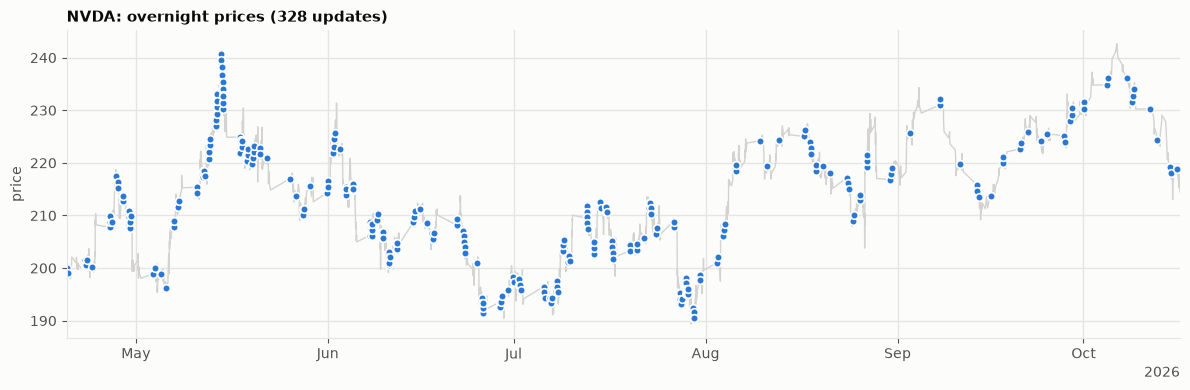

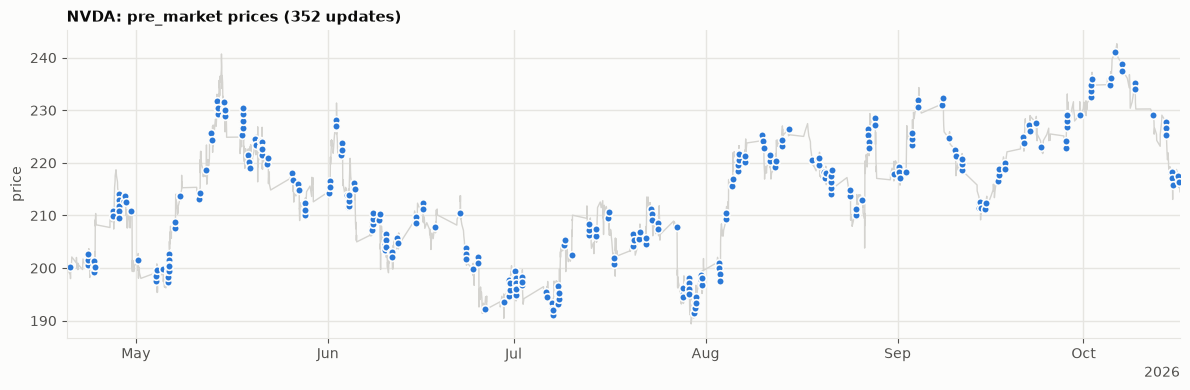

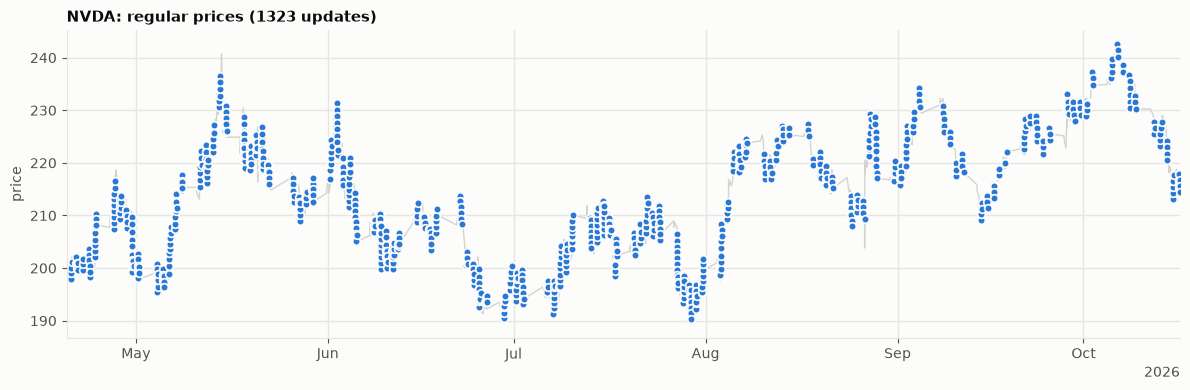

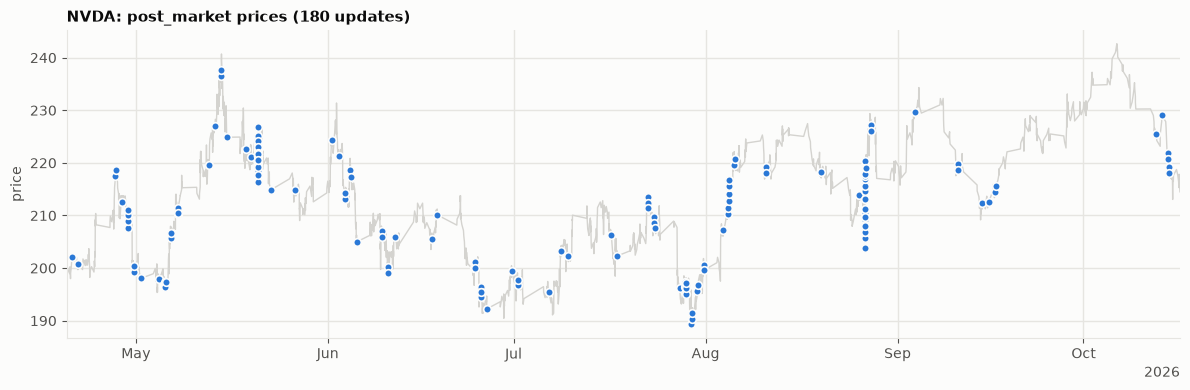

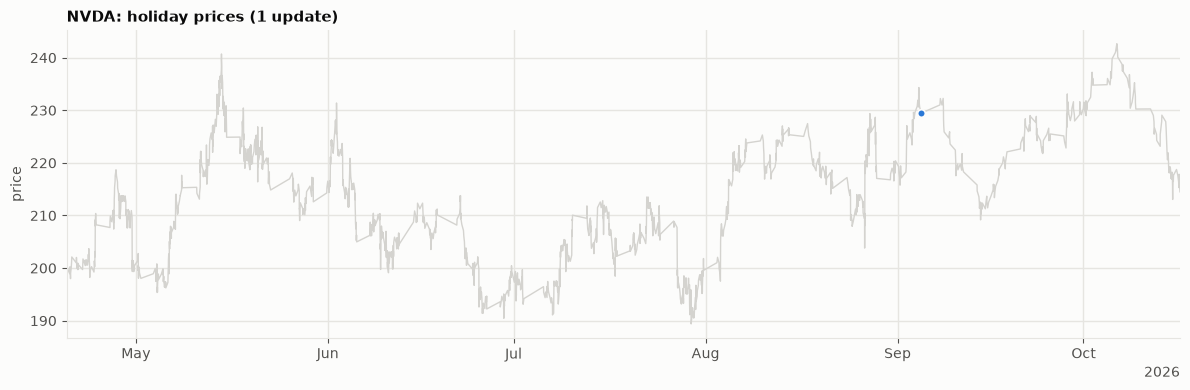

In [3]:
plot_prices(feeds["NVDA"])

### NVDA: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

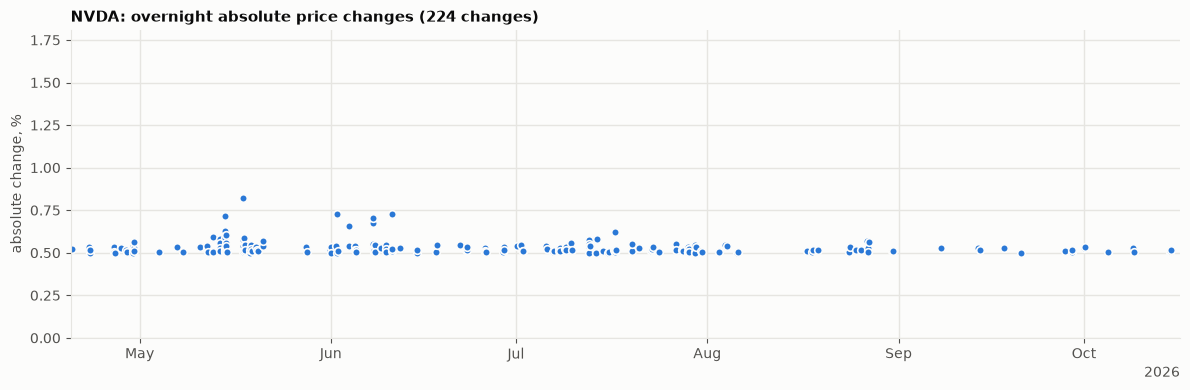

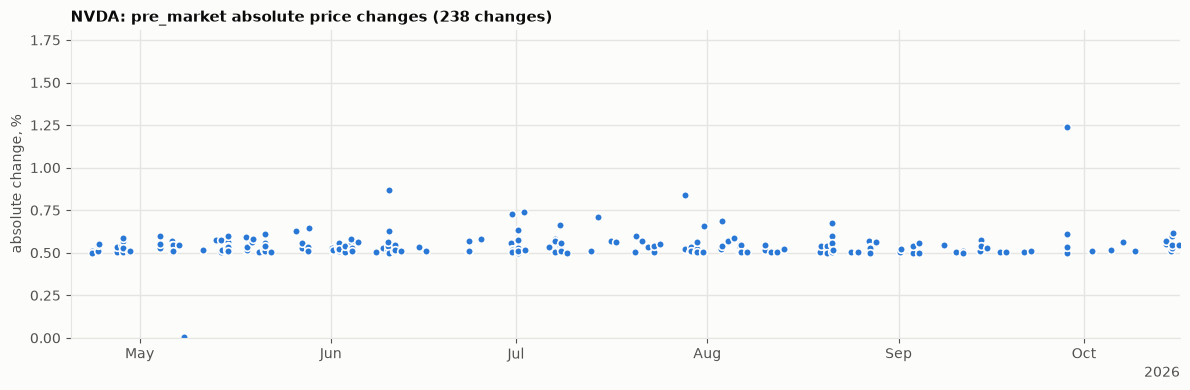

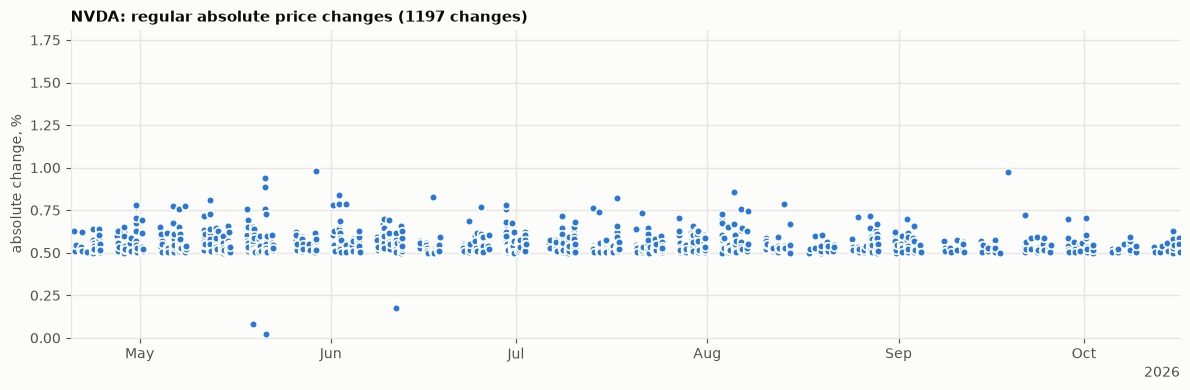

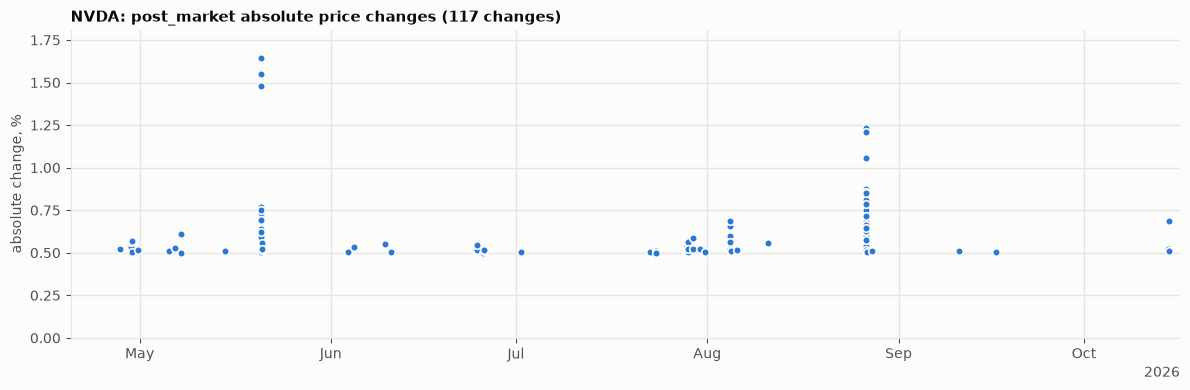

In [4]:
plot_changes(feeds["NVDA"])

### NVDA: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [5]:
session_type_stats(feeds["NVDA"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,126,328,224,0.5299,0.0416,0.5003,0.8226
pre_market,126,352,238,0.5421,0.0764,0.0023,1.2395
regular,126,1323,1197,0.5525,0.0645,0.0246,0.9784
post_market,126,180,117,0.6214,0.2006,0.5009,1.6444
weekend,23,0,0,NaN,NaN,NaN,NaN
holiday,4,1,0,NaN,NaN,NaN,NaN


### NVDA: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [6]:
transition_stats(feeds["NVDA"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,126,114,0.5284,0.0298,0.5002,0.6381
pre_market->regular,intraday,126,126,0.6076,0.1041,0.5001,1.1283
regular->post_market,intraday,126,63,0.5407,0.0457,0.5007,0.6756
post_market->overnight,intraday,100,78,0.5331,0.0403,0.5000,0.7314
post_market->overnight (weekend),closure,21,21,0.5066,0.5165,0.0087,2.0584
post_market->overnight (holiday),closure,4,4,0.8143,0.4429,0.1684,1.1715


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-04-24T20:00:00-04:00,post_market->overnight (weekend),regular,2026-04-24T14:29:35-04:00,208.2270,2026-04-26T20:00:47-04:00,207.7150,0,-0.2459,0.2459
2026-05-01T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-05-01T19:46:35-04:00,198.0445,2026-05-03T20:00:35-04:00,198.9250,0,0.4446,0.4446
2026-05-08T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-08T12:07:59-04:00,215.2759,2026-05-10T20:00:35-04:00,215.3550,0,0.0367,0.0367
2026-05-15T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-05-15T16:02:47-04:00,224.8716,2026-05-17T20:00:47-04:00,224.9050,0,0.0149,0.0149
2026-05-22T20:00:00-04:00,post_market->overnight (holiday),post_market,2026-05-22T18:41:23-04:00,214.8449,2026-05-25T20:02:11-04:00,216.9710,0,0.9896,0.9896
2026-05-29T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-29T15:54:35-04:00,212.5935,2026-05-31T20:01:59-04:00,214.2800,0,0.7933,0.7933
2026-06-05T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-06-05T16:01:47-04:00,204.9776,2026-06-07T20:00:35-04:00,206.2450,0,0.6183,0.6183
2026-06-12T20:00:00-04:00,post_market->overnight (weekend),regular,2026-06-12T12:42:59-04:00,204.5250,2026-06-14T20:00:47-04:00,208.7350,0,2.0584,2.0584
2026-06-18T20:00:00-04:00,post_market->overnight (holiday),post_market,2026-06-18T16:01:11-04:00,210.1189,2026-06-21T20:00:59-04:00,208.1700,0,-0.9275,0.9275


### NVDA: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [7]:
zero_answer_stats(feeds["NVDA"])

Zero answers: 0 of 2184 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,328,0,0.0000
pre_market,352,0,0.0000
regular,1323,0,0.0000
post_market,180,0,0.0000
weekend,0,0,NaN
holiday,1,0,0.0000


No session contains a zero answer.


### NVDA: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [8]:
unchanged_run_stats(feeds["NVDA"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


### NVDA: update rate and implied volatility

The first table gives one row for each open session type and one row for each closure transition type. The section [Update rate and implied volatility: formulas](#Update-rate-and-implied-volatility:-formulas) defines each column.

- `n_updates` includes all updates in the group. `n_threshold` includes only the threshold updates. `rate_per_h` uses `n_threshold`.
- `sigma_thr_h` and `sigma_rv_h` are in percent per hour. `sigma_session` is the volatility over one full session, in percent.
- In the rows `post_market->overnight (weekend)` and `post_market->overnight (holiday)`, `n_sessions` is the number of closures with a reopen update. `n_updates` is the number of reopen updates and updates inside a closure. `sigma_session` is the typical price change over one closure.

The second table gives the annualized volatility of the feed.

In [9]:
display(update_rate_table(feeds["NVDA"]))
display(annualized_volatility(feeds["NVDA"]).to_frame().T)

,n_sessions,hours,n_updates,n_threshold,empty_sessions_pct,updates_per_session,rate_per_h,mean_interval_min,sigma_thr_h,sigma_rv_h,overshoot_ratio,sigma_session,var_share_pct
group,,,,,,,,,,,,,
overnight,126,1008.0000,302,302,17.4603,2.3968,0.2996,200.2649,0.2730,0.2914,1.0672,0.8241,12.4014
pre_market,126,693.0000,352,351,9.5238,2.7937,0.5065,118.4615,0.3550,0.3860,1.0873,0.9051,14.9616
regular,126,819.0000,1323,1320,0.0000,10.5000,1.6117,37.2273,0.6332,0.7146,1.1286,1.8219,60.6168
post_market,126,504.0000,180,180,50.0000,1.4286,0.3571,168.0000,0.2981,0.3685,1.2362,0.7369,9.9168
post_market->overnight (weekend),21,1008.0000,21,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7108,1.5379
post_market->overnight (holiday),4,288.0000,5,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9877,0.5655


,trading_days,sigma_ann,sigma_ann_thr
NVDA,126.0000,37.1472,32.7283


### NVDA: update triggers and heartbeat check

The first table gives the number of updates for each trigger and the values that check the feed configuration:

- `min_abs_threshold_change_pct` is the smallest absolute change of a threshold update. It must be 0.5 or more.
- `max_open_gap_h` is the longest time between two updates outside closures. If it is less than 24 h, the heartbeat did not trigger an update.

The second table gives the reopen updates for each closure transition type. `median_delay_min` and `max_delay_min` give the time from the end of the closure to the reopen update. `below_threshold_pct` is the percentage of reopen updates with an absolute change of less than 0.5%.

The third table lists each `heartbeat` update and each `below_threshold` update.

In [10]:
trigger_check(feeds["NVDA"])

,NVDA
n_threshold,2154
n_reopen,25
n_heartbeat,0
n_below_threshold,4
min_abs_threshold_change_pct,0.5000
max_open_gap_h,21.0433
max_open_gap_end_et,2026-08-14T09:27:59-04:00


,n_reopen,median_delay_min,max_delay_min,below_threshold_pct
transition_type,,,,
post_market->overnight (weekend),21,0.5833,1.9833,57.1429
post_market->overnight (holiday),4,0.8833,2.1833,0.0000


,session_type,trigger,price,log_ret_pct,gap_h
updated_at_et,,,,,
2026-05-08T04:11:47-04:00,pre_market,below_threshold,213.7811,-0.0023,0.0100
2026-05-19T10:05:11-04:00,regular,below_threshold,219.9450,-0.0814,0.0500
2026-05-21T10:08:35-04:00,regular,below_threshold,223.9200,0.0246,0.0767
2026-06-11T15:11:59-04:00,regular,below_threshold,202.5400,0.1754,0.5300


## GOOGL

### GOOGL: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

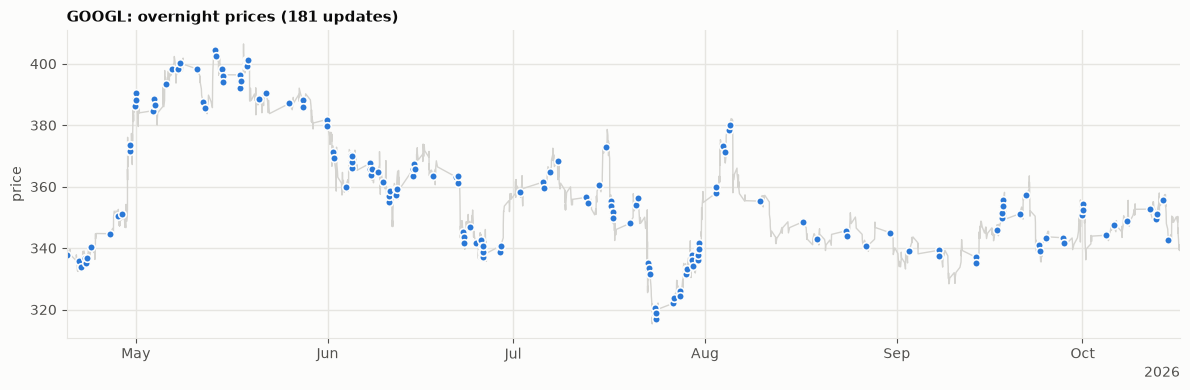

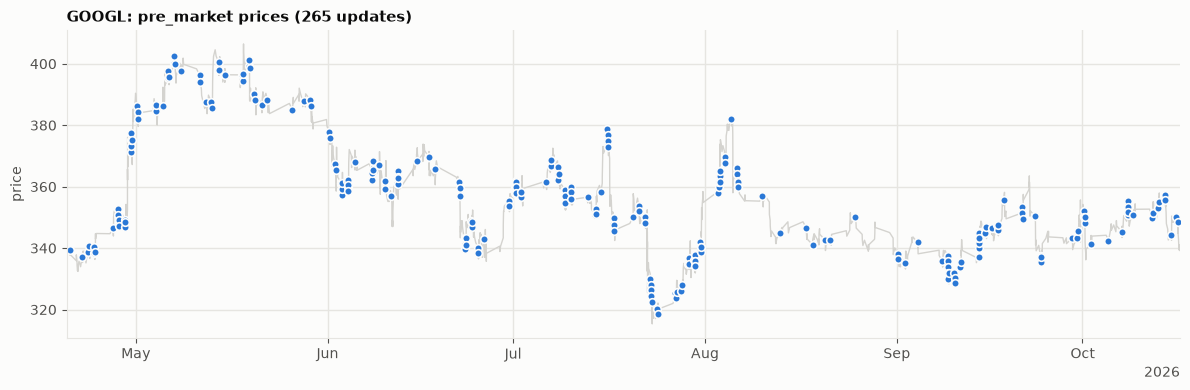

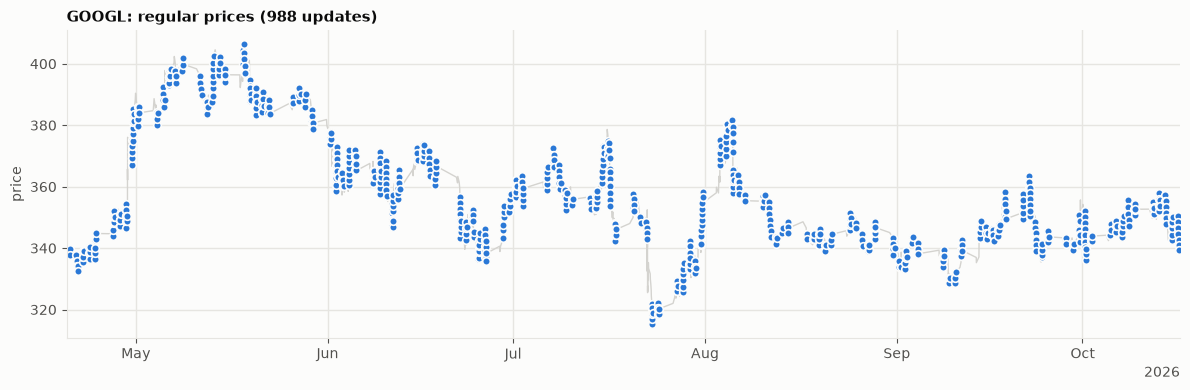

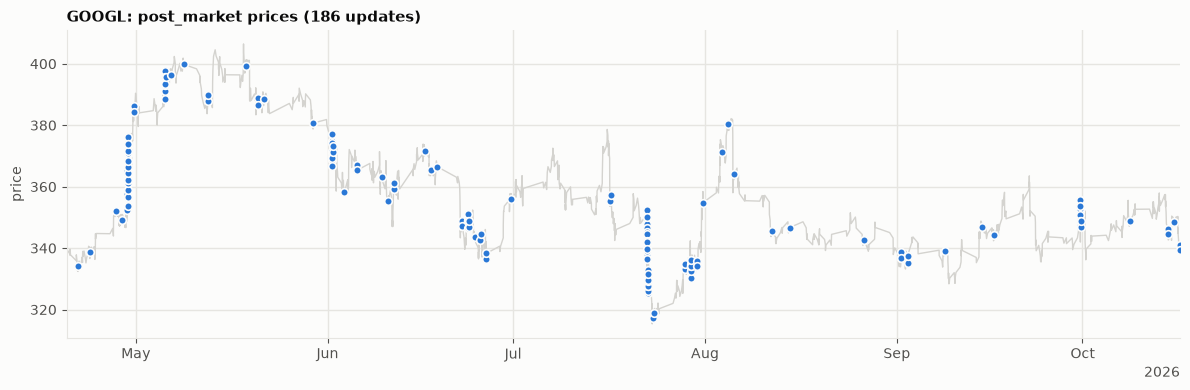

In [11]:
plot_prices(feeds["GOOGL"])

### GOOGL: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

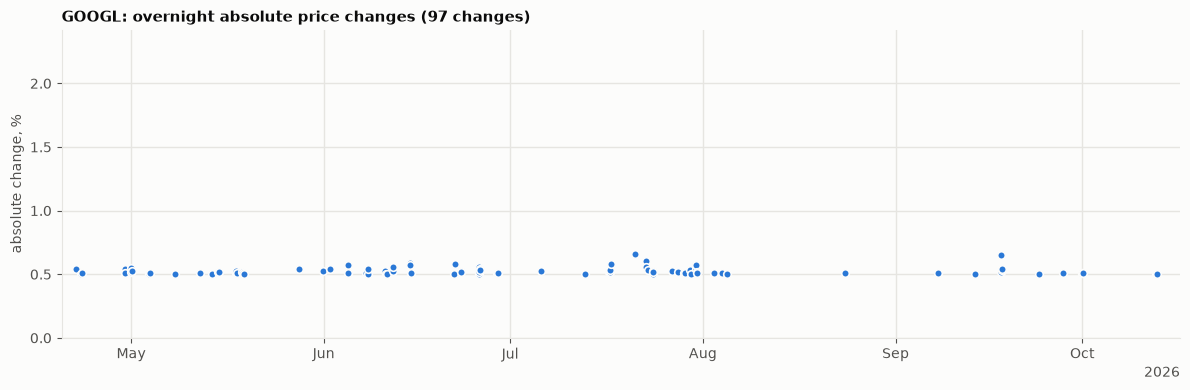

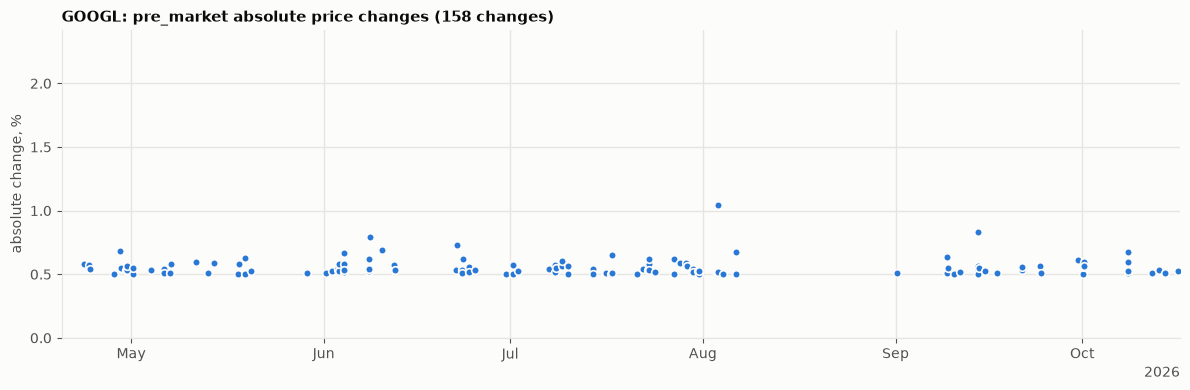

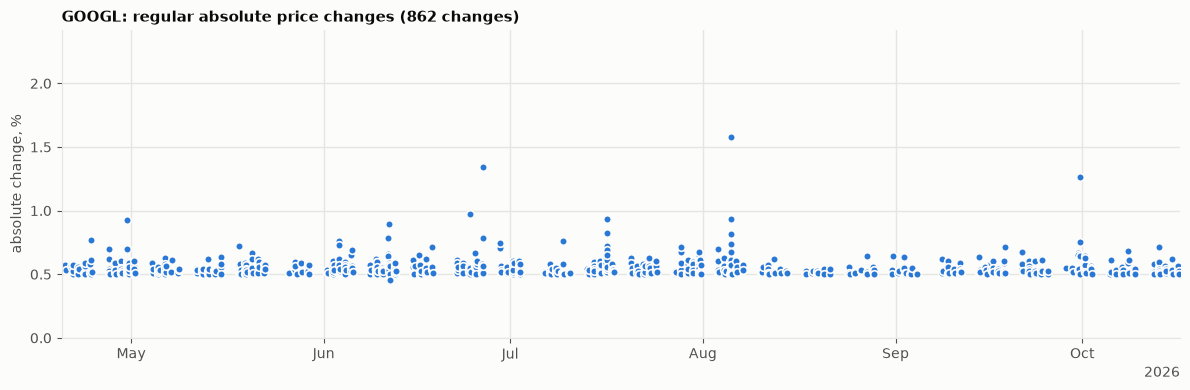

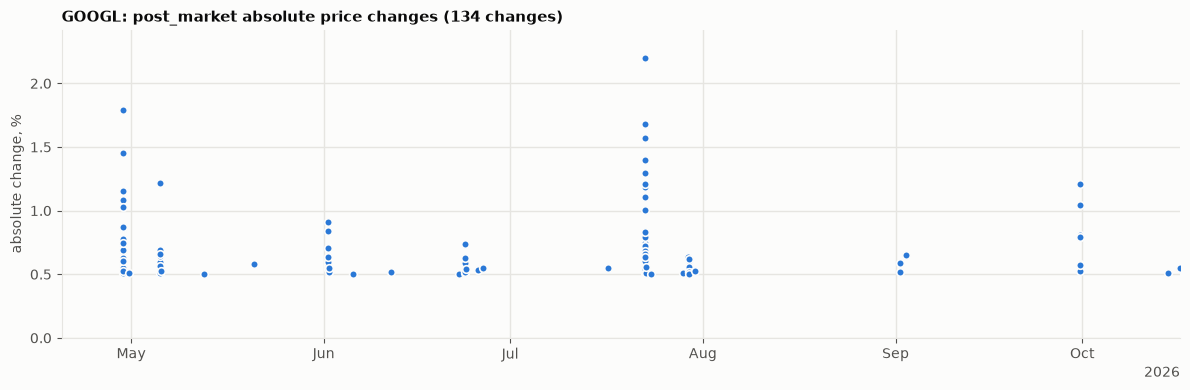

In [12]:
plot_changes(feeds["GOOGL"])

### GOOGL: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [13]:
session_type_stats(feeds["GOOGL"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,126,181,97,0.5253,0.0290,0.5002,0.6626
pre_market,126,265,158,0.5488,0.0665,0.5004,1.0427
regular,126,988,862,0.5507,0.0765,0.4554,1.5823
post_market,126,186,134,0.7019,0.2816,0.5023,2.1997
weekend,23,0,0,NaN,NaN,NaN,NaN
holiday,4,0,0,NaN,NaN,NaN,NaN


### GOOGL: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [14]:
transition_stats(feeds["GOOGL"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,126,107,0.5472,0.0664,0.5010,0.9278
pre_market->regular,intraday,126,126,0.6143,0.1242,0.5000,1.1804
regular->post_market,intraday,126,52,0.5948,0.3293,0.3024,2.7956
post_market->overnight,intraday,100,58,0.5202,0.0269,0.5002,0.6509
post_market->overnight (weekend),closure,21,21,0.4235,0.4086,0.0101,1.7925
post_market->overnight (holiday),closure,4,4,0.6774,0.2670,0.3468,0.9234


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-04-24T20:00:00-04:00,post_market->overnight (weekend),regular,2026-04-24T15:33:59-04:00,344.7550,2026-04-26T20:00:59-04:00,344.6850,0,-0.0203,0.0203
2026-05-01T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-01T14:36:23-04:00,384.0299,2026-05-03T20:00:35-04:00,384.7400,0,0.1849,0.1849
2026-05-08T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-05-08T17:44:59-04:00,399.8155,2026-05-10T20:00:23-04:00,398.3400,0,-0.3690,0.3690
2026-05-15T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-15T11:43:59-04:00,396.4150,2026-05-17T20:00:35-04:00,396.3750,0,-0.0101,0.0101
2026-05-22T20:00:00-04:00,post_market->overnight (holiday),regular,2026-05-22T15:09:23-04:00,383.7800,2026-05-25T20:01:59-04:00,387.0877,0,0.8619,0.8619
2026-05-29T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-05-29T16:01:35-04:00,380.6844,2026-05-31T20:00:59-04:00,381.8450,0,0.3049,0.3049
2026-06-05T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-06-05T18:28:47-04:00,365.3375,2026-06-07T20:00:35-04:00,367.5600,0,0.6083,0.6083
2026-06-12T20:00:00-04:00,post_market->overnight (weekend),regular,2026-06-12T15:46:35-04:00,359.2650,2026-06-14T20:00:23-04:00,365.7050,0,1.7925,1.7925
2026-06-18T20:00:00-04:00,post_market->overnight (holiday),post_market,2026-06-18T18:20:35-04:00,366.4536,2026-06-21T20:00:47-04:00,363.0700,0,-0.9234,0.9234


### GOOGL: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [15]:
zero_answer_stats(feeds["GOOGL"])

Zero answers: 0 of 1620 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,181,0,0.0000
pre_market,265,0,0.0000
regular,988,0,0.0000
post_market,186,0,0.0000
weekend,0,0,NaN
holiday,0,0,NaN


No session contains a zero answer.


### GOOGL: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [16]:
unchanged_run_stats(feeds["GOOGL"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


### GOOGL: update rate and implied volatility

The first table gives one row for each open session type and one row for each closure transition type. The section [Update rate and implied volatility: formulas](#Update-rate-and-implied-volatility:-formulas) defines each column.

- `n_updates` includes all updates in the group. `n_threshold` includes only the threshold updates. `rate_per_h` uses `n_threshold`.
- `sigma_thr_h` and `sigma_rv_h` are in percent per hour. `sigma_session` is the volatility over one full session, in percent.
- In the rows `post_market->overnight (weekend)` and `post_market->overnight (holiday)`, `n_sessions` is the number of closures with a reopen update. `n_updates` is the number of reopen updates and updates inside a closure. `sigma_session` is the typical price change over one closure.

The second table gives the annualized volatility of the feed.

In [17]:
display(update_rate_table(feeds["GOOGL"]))
display(annualized_volatility(feeds["GOOGL"]).to_frame().T)

,n_sessions,hours,n_updates,n_threshold,empty_sessions_pct,updates_per_session,rate_per_h,mean_interval_min,sigma_thr_h,sigma_rv_h,overshoot_ratio,sigma_session,var_share_pct
group,,,,,,,,,,,,,
overnight,126,1008.0000,155,155,33.3333,1.2302,0.1538,390.1935,0.1956,0.2056,1.0512,0.5815,7.7624
pre_market,126,693.0000,265,265,15.0794,2.1032,0.3824,156.9057,0.3084,0.3415,1.1072,0.8009,14.7231
regular,126,819.0000,988,987,0.0000,7.8413,1.2051,49.7872,0.5475,0.6211,1.1344,1.5836,57.5678
post_market,126,504.0000,186,185,58.7302,1.4762,0.3671,163.4595,0.3022,0.4463,1.4771,0.8927,18.2920
post_market->overnight (weekend),21,1008.0000,21,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5787,1.2815
post_market->overnight (holiday),4,288.0000,4,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7156,0.3732


,trading_days,sigma_ann,sigma_ann_thr
GOOGL,126.0000,33.1324,28.1432


### GOOGL: update triggers and heartbeat check

The first table gives the number of updates for each trigger and the values that check the feed configuration:

- `min_abs_threshold_change_pct` is the smallest absolute change of a threshold update. It must be 0.5 or more.
- `max_open_gap_h` is the longest time between two updates outside closures. If it is less than 24 h, the heartbeat did not trigger an update.

The second table gives the reopen updates for each closure transition type. `median_delay_min` and `max_delay_min` give the time from the end of the closure to the reopen update. `below_threshold_pct` is the percentage of reopen updates with an absolute change of less than 0.5%.

The third table lists each `heartbeat` update and each `below_threshold` update.

In [18]:
trigger_check(feeds["GOOGL"])

,GOOGL
n_threshold,1592
n_reopen,25
n_heartbeat,0
n_below_threshold,2
min_abs_threshold_change_pct,0.5000
max_open_gap_h,23.0467
max_open_gap_end_et,2026-08-26T09:30:35-04:00


,n_reopen,median_delay_min,max_delay_min,below_threshold_pct
transition_type,,,,
post_market->overnight (weekend),21,0.5833,0.9833,61.9048
post_market->overnight (holiday),4,0.7833,1.9833,25.0000


,session_type,trigger,price,log_ret_pct,gap_h
updated_at_et,,,,,
2026-05-20T16:23:23-04:00,post_market,below_threshold,388.8846,0.3020,1.4767
2026-06-11T15:03:11-04:00,regular,below_threshold,355.3460,0.4544,0.7400


## TSLA

### TSLA: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

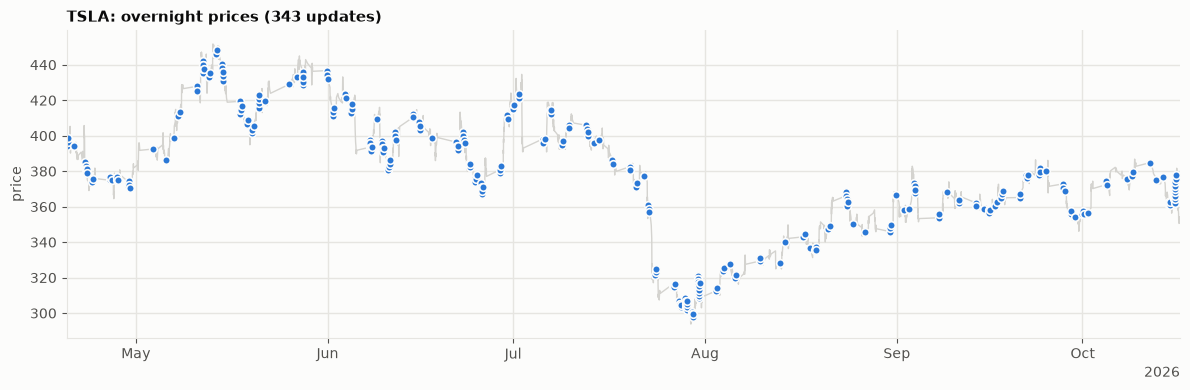

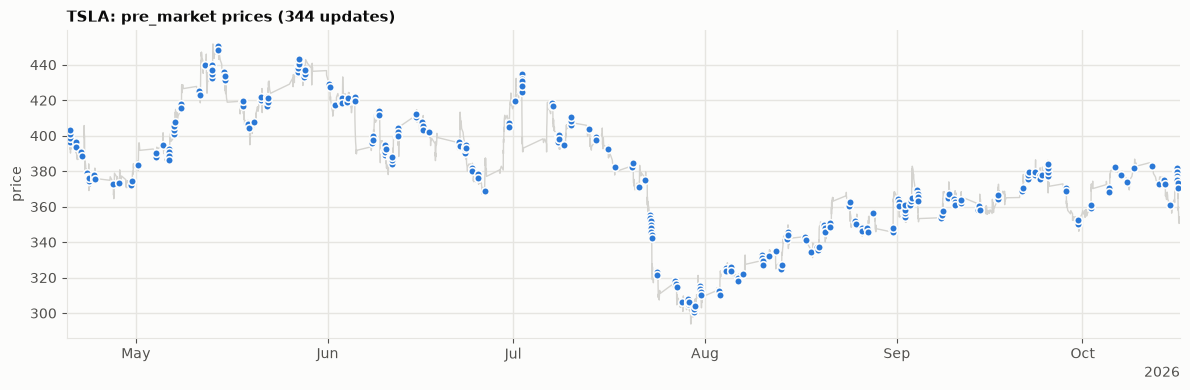

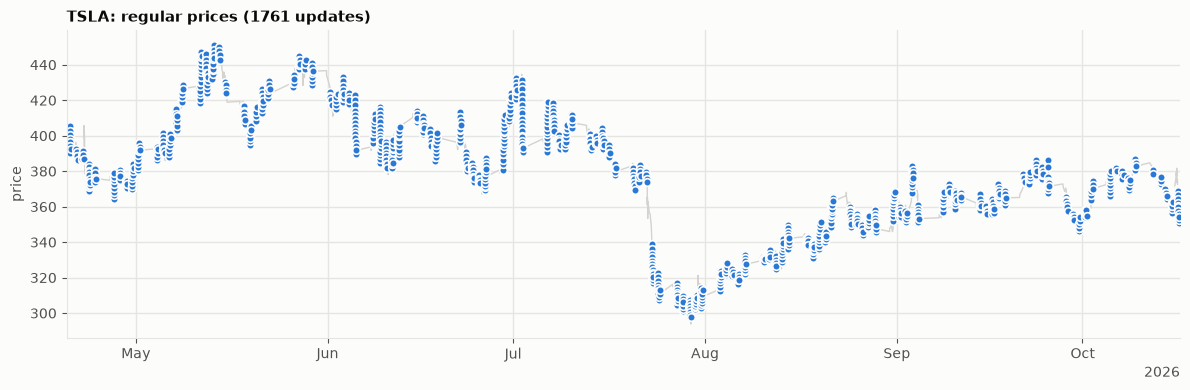

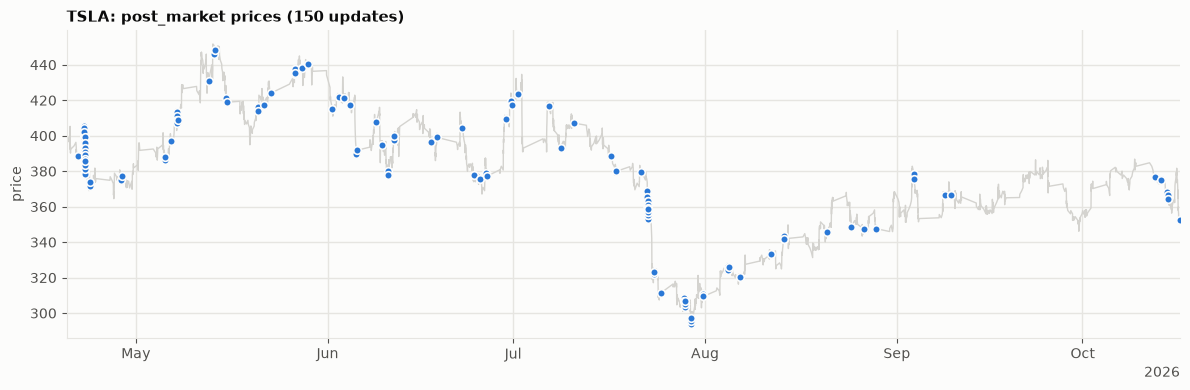

In [19]:
plot_prices(feeds["TSLA"])

### TSLA: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

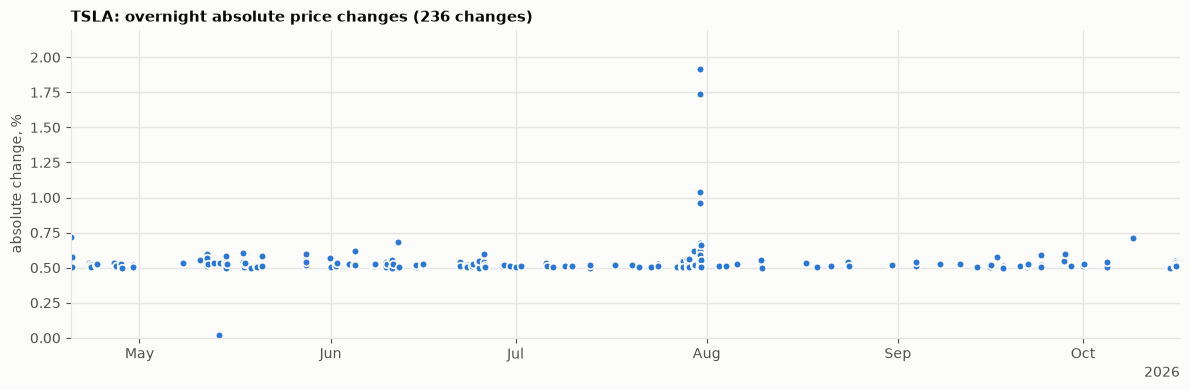

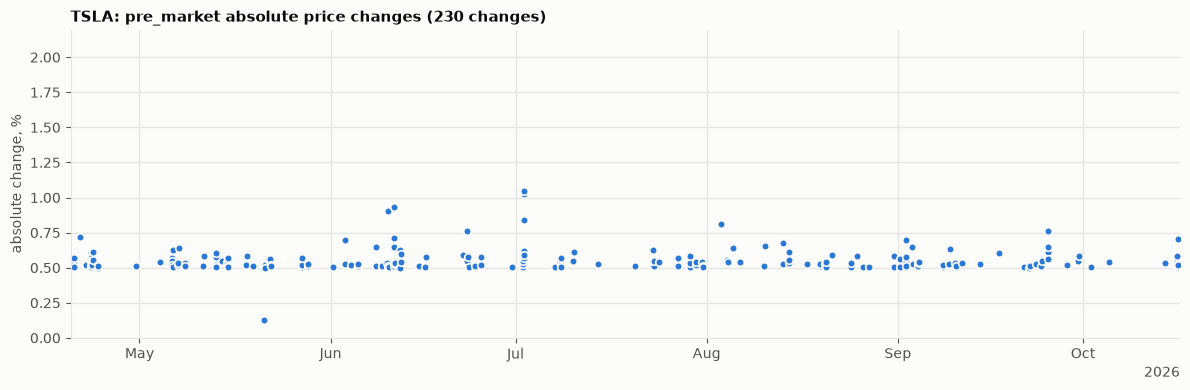

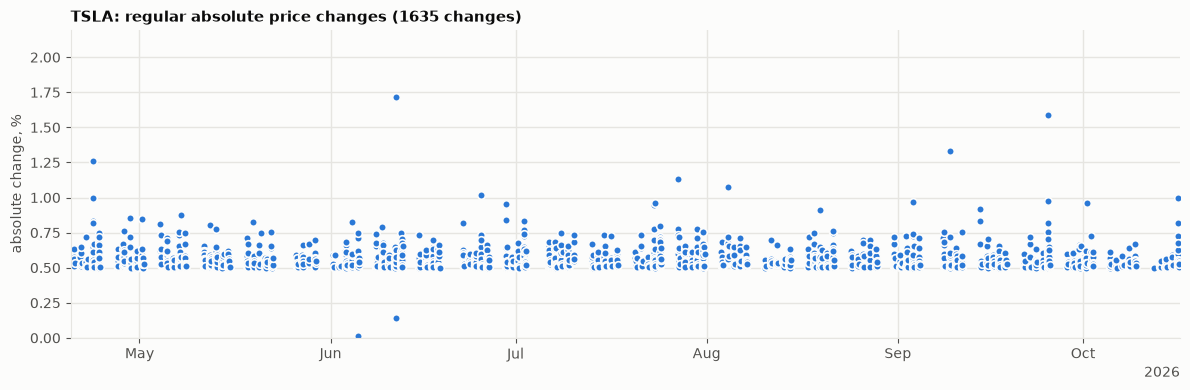

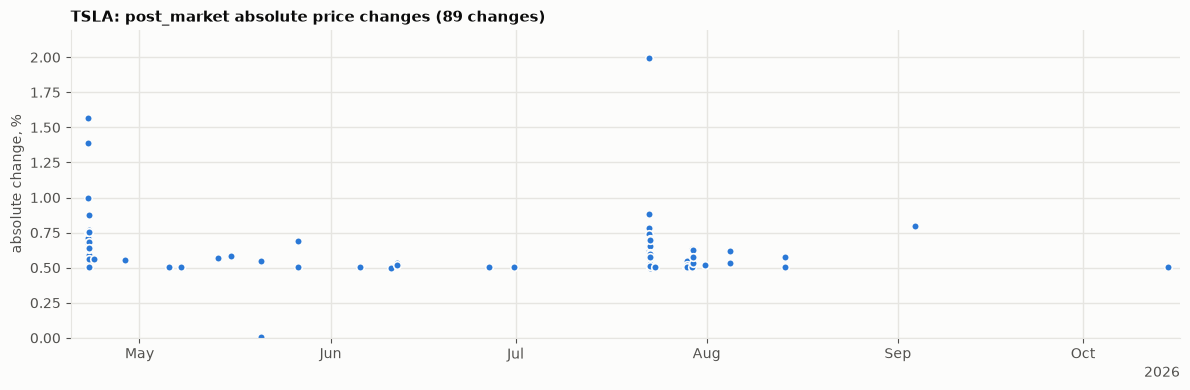

In [20]:
plot_changes(feeds["TSLA"])

### TSLA: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [21]:
session_type_stats(feeds["TSLA"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,126,343,236,0.5427,0.1360,0.0191,1.9168
pre_market,126,344,230,0.5540,0.0843,0.1262,1.0445
regular,126,1761,1635,0.5669,0.0881,0.0159,1.7145
post_market,126,150,89,0.6257,0.2313,0.0048,1.9948
weekend,23,0,0,NaN,NaN,NaN,NaN
holiday,4,0,0,NaN,NaN,NaN,NaN


### TSLA: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [22]:
transition_stats(feeds["TSLA"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,126,114,0.5356,0.0518,0.5001,0.8920
pre_market->regular,intraday,126,126,0.6532,0.1380,0.5018,1.3207
regular->post_market,intraday,126,61,0.5615,0.2133,0.0442,1.9343
post_market->overnight,intraday,100,81,0.5262,0.0351,0.5001,0.6813
post_market->overnight (weekend),closure,21,21,0.5683,0.4250,0.0416,1.6641
post_market->overnight (holiday),closure,4,4,0.8351,0.5506,0.1234,1.3243


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-04-24T20:00:00-04:00,post_market->overnight (weekend),regular,2026-04-24T13:09:59-04:00,375.8378,2026-04-26T20:00:35-04:00,374.8700,0,-0.2575,0.2575
2026-05-01T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-01T15:44:23-04:00,391.7500,2026-05-03T20:00:47-04:00,392.5100,0,0.1940,0.1940
2026-05-08T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-08T14:55:47-04:00,426.5150,2026-05-10T20:00:59-04:00,427.7850,0,0.2978,0.2978
2026-05-15T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-05-15T18:56:23-04:00,418.8990,2026-05-17T20:00:35-04:00,419.3900,0,0.1172,0.1172
2026-05-22T20:00:00-04:00,post_market->overnight (holiday),post_market,2026-05-22T18:47:47-04:00,423.9072,2026-05-25T20:01:47-04:00,429.0360,0,1.2099,1.2099
2026-05-29T20:00:00-04:00,post_market->overnight (weekend),regular,2026-05-29T14:04:47-04:00,436.3100,2026-05-31T20:00:35-04:00,436.7000,0,0.0894,0.0894
2026-06-05T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-06-05T17:25:47-04:00,391.7744,2026-06-07T20:00:35-04:00,393.5550,0,0.4545,0.4545
2026-06-12T20:00:00-04:00,post_market->overnight (weekend),regular,2026-06-12T15:56:11-04:00,405.1850,2026-06-14T20:00:35-04:00,410.3950,0,1.2858,1.2858
2026-06-18T20:00:00-04:00,post_market->overnight (holiday),post_market,2026-06-18T16:03:35-04:00,399.0639,2026-06-21T20:00:59-04:00,396.3400,0,-0.6826,0.6826


### TSLA: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [23]:
zero_answer_stats(feeds["TSLA"])

Zero answers: 0 of 2598 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,343,0,0.0000
pre_market,344,0,0.0000
regular,1761,0,0.0000
post_market,150,0,0.0000
weekend,0,0,NaN
holiday,0,0,NaN


No session contains a zero answer.


### TSLA: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [24]:
unchanged_run_stats(feeds["TSLA"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


### TSLA: update rate and implied volatility

The first table gives one row for each open session type and one row for each closure transition type. The section [Update rate and implied volatility: formulas](#Update-rate-and-implied-volatility:-formulas) defines each column.

- `n_updates` includes all updates in the group. `n_threshold` includes only the threshold updates. `rate_per_h` uses `n_threshold`.
- `sigma_thr_h` and `sigma_rv_h` are in percent per hour. `sigma_session` is the volatility over one full session, in percent.
- In the rows `post_market->overnight (weekend)` and `post_market->overnight (holiday)`, `n_sessions` is the number of closures with a reopen update. `n_updates` is the number of reopen updates and updates inside a closure. `sigma_session` is the typical price change over one closure.

The second table gives the annualized volatility of the feed.

In [25]:
display(update_rate_table(feeds["TSLA"]))
display(annualized_volatility(feeds["TSLA"]).to_frame().T)

,n_sessions,hours,n_updates,n_threshold,empty_sessions_pct,updates_per_session,rate_per_h,mean_interval_min,sigma_thr_h,sigma_rv_h,overshoot_ratio,sigma_session,var_share_pct
group,,,,,,,,,,,,,
overnight,126,1008.0000,317,316,15.0794,2.5159,0.3135,191.3924,0.2793,0.3092,1.1072,0.8745,11.0566
pre_market,126,693.0000,344,343,9.5238,2.7302,0.4949,121.2245,0.3509,0.3897,1.1107,0.9140,12.0782
regular,126,819.0000,1761,1759,0.0000,13.9762,2.1477,27.9363,0.7309,0.8518,1.1654,2.1718,68.1884
post_market,126,504.0000,150,148,51.5873,1.1905,0.2937,204.3243,0.2703,0.3498,1.2941,0.6995,7.0747
post_market->overnight (weekend),21,1008.0000,21,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7004,1.1820
post_market->overnight (holiday),4,288.0000,4,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9568,0.4201


,trading_days,sigma_ann,sigma_ann_thr
TSLA,126.0000,41.7504,35.7297


### TSLA: update triggers and heartbeat check

The first table gives the number of updates for each trigger and the values that check the feed configuration:

- `min_abs_threshold_change_pct` is the smallest absolute change of a threshold update. It must be 0.5 or more.
- `max_open_gap_h` is the longest time between two updates outside closures. If it is less than 24 h, the heartbeat did not trigger an update.

The second table gives the reopen updates for each closure transition type. `median_delay_min` and `max_delay_min` give the time from the end of the closure to the reopen update. `below_threshold_pct` is the percentage of reopen updates with an absolute change of less than 0.5%.

The third table lists each `heartbeat` update and each `below_threshold` update.

In [26]:
trigger_check(feeds["TSLA"])

,TSLA
n_threshold,2566
n_reopen,25
n_heartbeat,0
n_below_threshold,6
min_abs_threshold_change_pct,0.5000
max_open_gap_h,18.8467
max_open_gap_end_et,2026-05-05T08:07:59-04:00


,n_reopen,median_delay_min,max_delay_min,below_threshold_pct
transition_type,,,,
post_market->overnight (weekend),21,0.5833,0.9833,52.3810
post_market->overnight (holiday),4,0.8833,1.7833,25.0000


,session_type,trigger,price,log_ret_pct,gap_h
updated_at_et,,,,,
2026-05-13T21:53:23-04:00,overnight,below_threshold,446.0650,-0.0191,0.0933
2026-05-20T16:25:59-04:00,post_market,below_threshold,416.0446,-0.0443,0.5067
2026-05-20T16:29:11-04:00,post_market,below_threshold,416.0646,0.0048,0.0533
2026-05-21T06:30:59-04:00,pre_market,below_threshold,419.9021,-0.1262,0.0033
2026-06-05T10:09:11-04:00,regular,below_threshold,409.4400,-0.0159,0.0167
2026-06-11T15:07:47-04:00,regular,below_threshold,393.2600,0.1386,0.8633


## SPCX

### SPCX: prices by session type

There is one plot for each session type. Each plot shows the updates of that session type as blue points. The gray line shows all updates of the feed. A session type without updates has no plot.

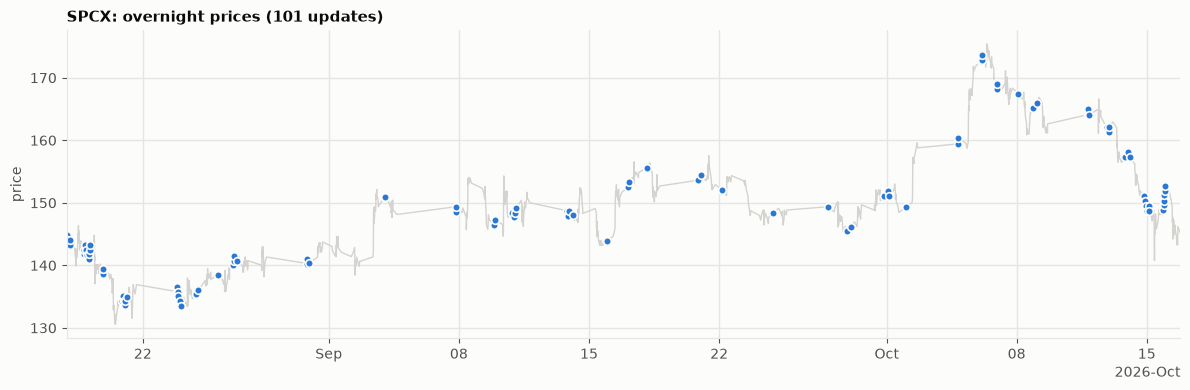

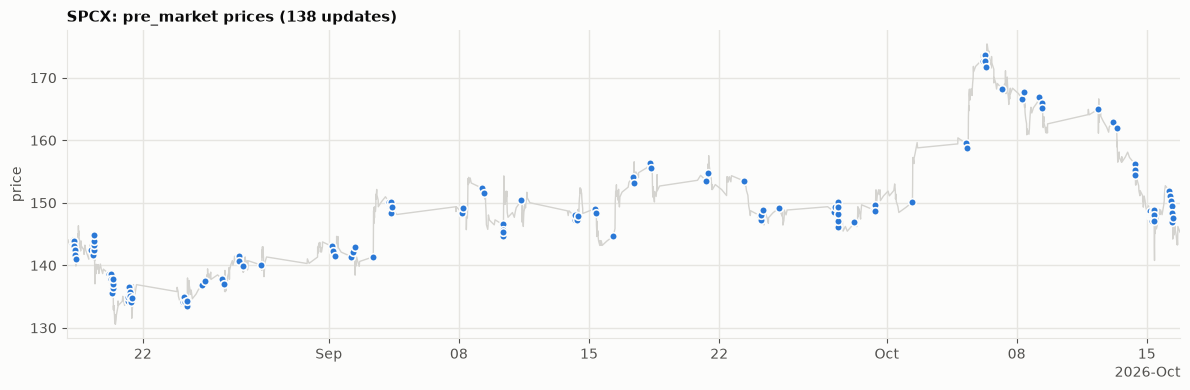

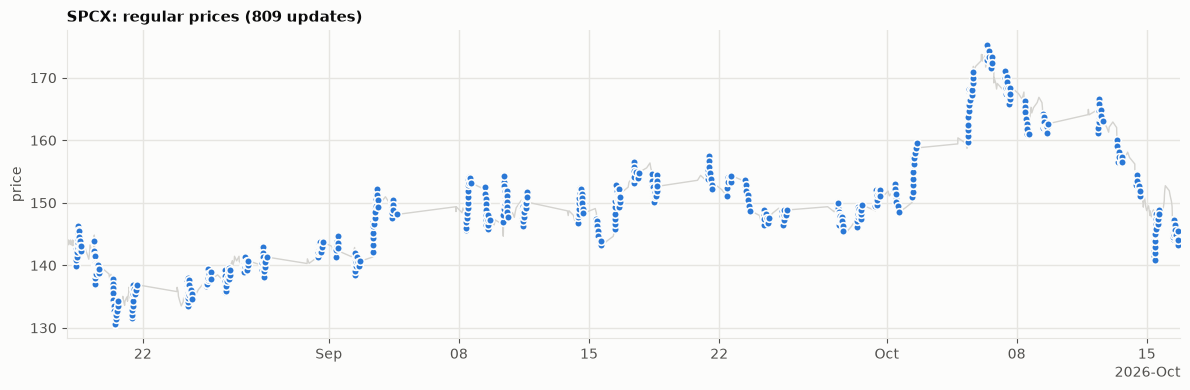

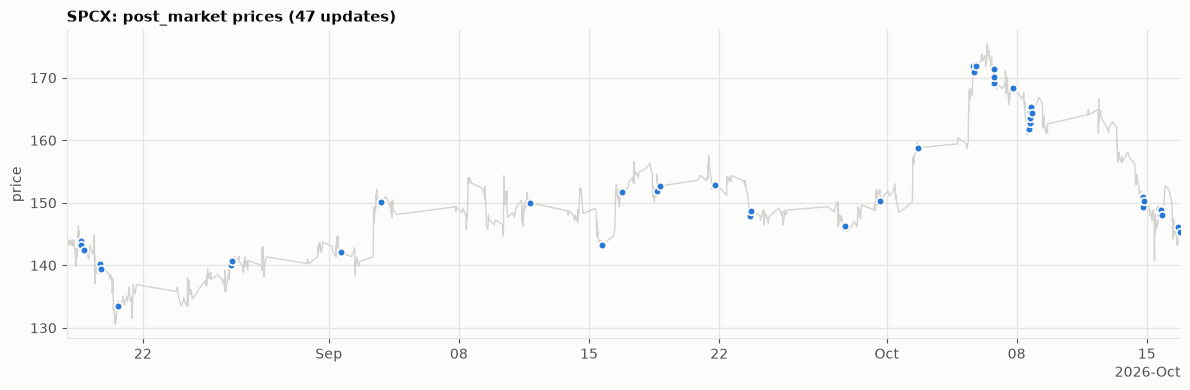

In [27]:
plot_prices(feeds["SPCX"])

### SPCX: absolute price changes by session type

There is one plot for each session type. Each plot shows the absolute price change in a session for the updates of that session type. All plots use the same axis limits. The first update of a session has no price change, so the plot does not show it. A session type without price changes has no plot.

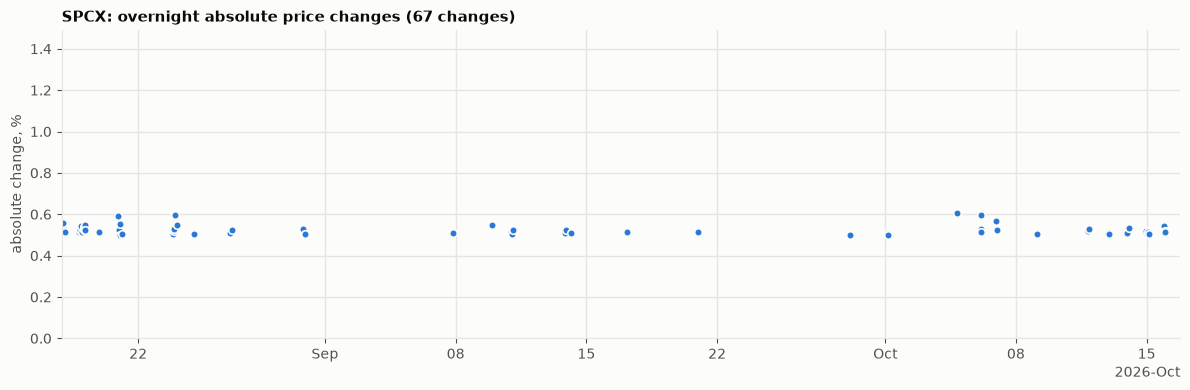

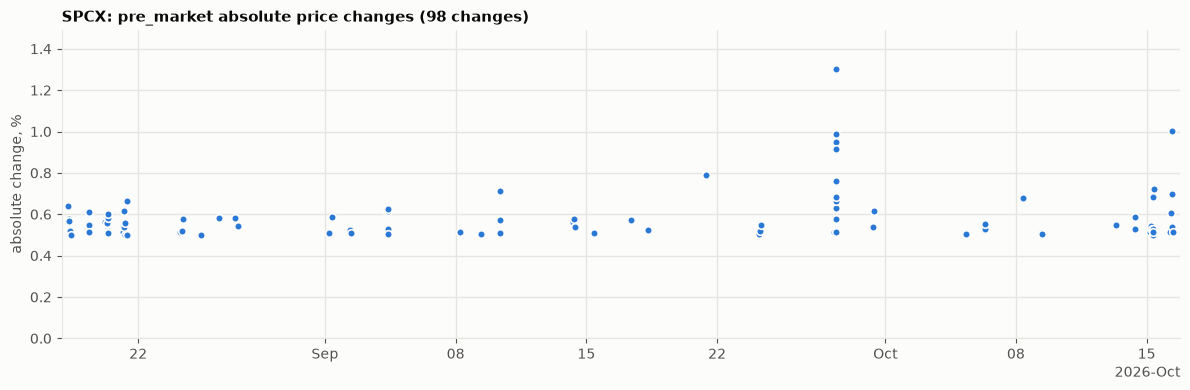

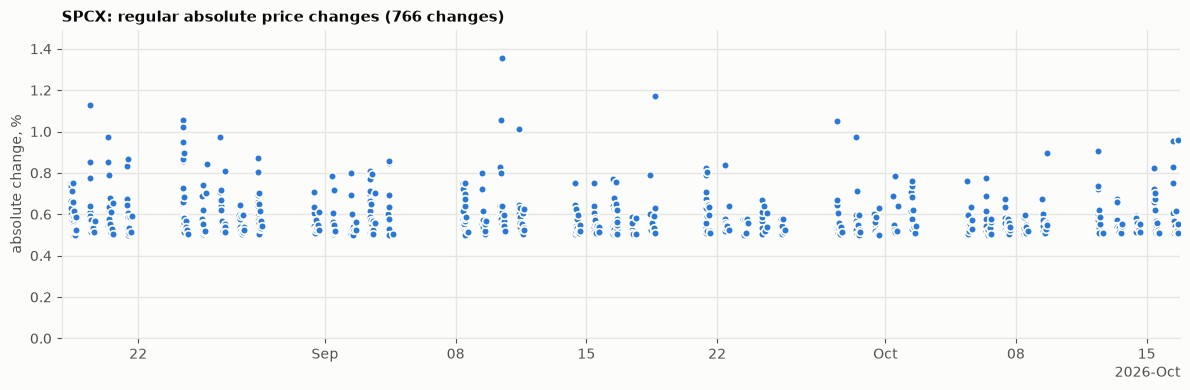

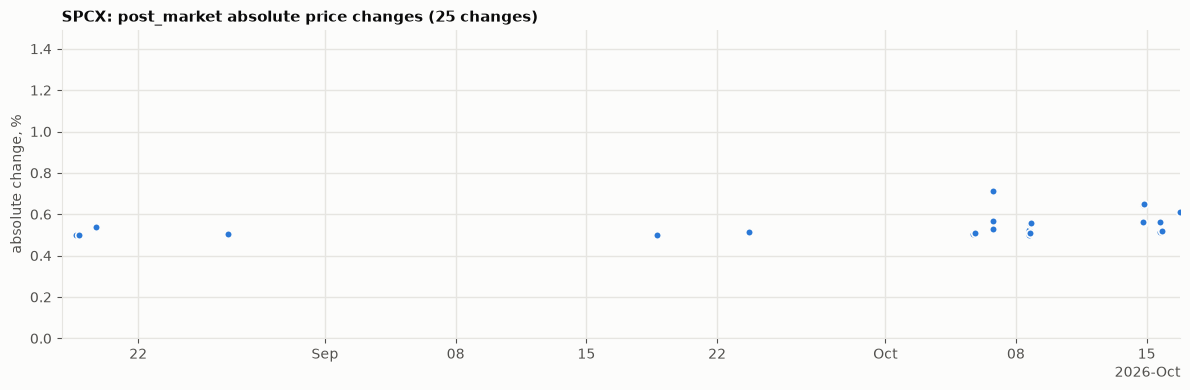

In [28]:
plot_changes(feeds["SPCX"])

### SPCX: statistics for each session type

The table gives the number of sessions, updates and price changes for each session type. It also gives the mean, the standard deviation, the minimum and the maximum of the absolute price change in a session.

In [29]:
session_type_stats(feeds["SPCX"])

,n_sessions,n_updates,n_changes,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
session_type,,,,,,,
overnight,43,101,67,0.5246,0.0239,0.5004,0.6053
pre_market,43,138,98,0.5847,0.1251,0.5010,1.3023
regular,43,809,766,0.5841,0.1024,0.5002,1.3555
post_market,44,47,25,0.5478,0.0547,0.5001,0.7137
weekend,8,0,0,NaN,NaN,NaN,NaN
holiday,1,0,0,NaN,NaN,NaN,NaN


### SPCX: statistics for each transition type

The first table gives one row for each transition type. `n` is the number of session boundaries. `n_with_price` is the number of boundaries with a price change. The other columns give the mean, the standard deviation, the minimum and the maximum of the absolute price change.

The second table gives one row for each weekend closure and each holiday closure. It shows the two prices, the session of the first price and the signed price change. The column `updates_during_closure` gives the number of updates that the calculation does not use.

In [30]:
transition_stats(feeds["SPCX"])

,category,n,n_with_price,mean_abs_pct,std_abs_pct,min_abs_pct,max_abs_pct
transition_type,,,,,,,
overnight->pre_market,intraday,43,40,0.5404,0.0563,0.5017,0.8092
pre_market->regular,intraday,43,43,0.6898,0.1771,0.5110,1.2433
regular->post_market,intraday,43,22,0.5410,0.0360,0.5040,0.6295
post_market->overnight,intraday,35,25,0.5205,0.0169,0.5003,0.5579
post_market->overnight (weekend),closure,7,7,0.6671,0.2220,0.3534,0.9030
post_market->overnight (holiday),closure,1,1,0.8360,NaN,0.8360,0.8360


,transition_type,price_before_session,price_before_et,price_before,price_after_et,price_after,updates_during_closure,pct_change,abs_pct_change
closure_start_et,,,,,,,,,
2026-08-21T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-21T15:48:47-04:00,136.9150,2026-08-23T20:00:47-04:00,135.8000,0,-0.8144,0.8144
2026-08-28T20:00:00-04:00,post_market->overnight (weekend),regular,2026-08-28T15:41:23-04:00,141.3390,2026-08-30T20:00:35-04:00,140.2950,0,-0.7386,0.7386
2026-09-04T20:00:00-04:00,post_market->overnight (holiday),regular,2026-09-04T15:53:47-04:00,148.1350,2026-09-07T20:00:47-04:00,149.3734,0,0.8360,0.8360
2026-09-11T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-09-11T19:39:35-04:00,150.0139,2026-09-13T20:00:35-04:00,148.7200,0,-0.8626,0.8626
2026-09-18T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-09-18T19:02:47-04:00,152.6849,2026-09-20T20:00:23-04:00,153.6000,0,0.5993,0.5993
2026-09-25T20:00:00-04:00,post_market->overnight (weekend),regular,2026-09-25T15:39:11-04:00,148.8490,2026-09-27T20:00:35-04:00,149.3750,0,0.3534,0.3534
2026-10-02T20:00:00-04:00,post_market->overnight (weekend),post_market,2026-10-02T16:08:35-04:00,158.7920,2026-10-04T20:00:47-04:00,159.4250,0,0.3986,0.3986
2026-10-09T20:00:00-04:00,post_market->overnight (weekend),regular,2026-10-09T15:55:47-04:00,162.6265,2026-10-11T20:00:59-04:00,164.0950,0,0.9030,0.9030


### SPCX: zero answers

The output gives the total number of zero answers. The first table gives the zero answers for each session type. The second table lists each session that contains a zero answer.

In [31]:
zero_answer_stats(feeds["SPCX"])

Zero answers: 0 of 1095 updates


,n_updates,n_zero,zero_share_pct
session_type,,,
overnight,101,0,0.0000
pre_market,138,0,0.0000
regular,809,0,0.0000
post_market,47,0,0.0000
weekend,0,0,NaN
holiday,0,0,NaN


No session contains a zero answer.


### SPCX: unchanged runs

The output gives the total number of unchanged runs and the longest run. The first table gives the runs for each session type. The second table lists each session that contains a run.

In [32]:
unchanged_run_stats(feeds["SPCX"])

Unchanged runs: 0, with 0 updates in total
Longest run: none


,n_runs,n_updates_in_runs,longest_run
session_type,,,
overnight,0,0,0
pre_market,0,0,0
regular,0,0,0
post_market,0,0,0
weekend,0,0,0
holiday,0,0,0


No session contains an unchanged run.


## Overall statistics

This section compares NVDA, GOOGL and TSLA. All 3 feeds use the same 6-month time window. SPCX is not included, because its data covers only 2 months and is not new.

### Data overview and data quality

One row for each stock. `round_gaps` is the number of missing round IDs between two consecutive updates. `zero_answers` and `unchanged_runs` use the definitions in the section [Method](#Method).

In [33]:
overview = pd.DataFrame({
    symbol: {
        "start_utc": feeds[symbol]["meta"]["start"][:16],
        "end_utc": feeds[symbol]["meta"]["end"][:16],
        "trading_days": _n_trading_days(feeds[symbol]),
        "closures": int((feeds[symbol]["updates"]["trigger"] == "reopen").sum()),
        "updates": len(feeds[symbol]["prices"]),
        "updates_per_trading_day": len(feeds[symbol]["prices"]) / _n_trading_days(feeds[symbol]),
        "round_gaps": int((feeds[symbol]["prices"]["round_id"].diff().dropna() != 1).sum()),
        "zero_answers": int((feeds[symbol]["prices"]["answer_raw"] == 0).sum()),
        "unchanged_runs": len(feeds[symbol]["runs"]),
    }
    for symbol in RESEARCHED
}).T
overview

,start_utc,end_utc,trading_days,closures,updates,updates_per_trading_day,round_gaps,zero_answers,unchanged_runs
NVDA,2026-04-18T17:35,2026-10-18T17:35,126,25,2184,17.3333,0,0,0
GOOGL,2026-04-18T17:35,2026-10-18T17:35,126,25,1620,12.8571,0,0,0
TSLA,2026-04-18T17:35,2026-10-18T17:35,126,25,2598,20.6190,0,0,0


### Update rate and implied volatility by group

The tables compare the 3 stocks for each open session type and each closure transition type:

1. `rate_per_h`: threshold updates per hour.
2. `sigma_rv_h`: realized volatility, in percent per hour.
3. `overshoot_ratio`: the typical size of one update divided by the threshold.
4. `var_share_pct`: the percentage of the total price variance in each group.
5. `empty_sessions_pct`: the percentage of sessions without an update.

In [34]:
rate_tables = {symbol: update_rate_table(feeds[symbol]) for symbol in RESEARCHED}
for column in ["rate_per_h", "sigma_rv_h", "overshoot_ratio", "var_share_pct", "empty_sessions_pct"]:
    pivot = pd.DataFrame({symbol: table[column] for symbol, table in rate_tables.items()}).T
    pivot = pivot.dropna(axis=1, how="all")
    pivot.columns.name = column
    display(pivot)

rate_per_h,overnight,pre_market,regular,post_market
NVDA,0.2996,0.5065,1.6117,0.3571
GOOGL,0.1538,0.3824,1.2051,0.3671
TSLA,0.3135,0.4949,2.1477,0.2937


sigma_rv_h,overnight,pre_market,regular,post_market
NVDA,0.2914,0.3860,0.7146,0.3685
GOOGL,0.2056,0.3415,0.6211,0.4463
TSLA,0.3092,0.3897,0.8518,0.3498


overshoot_ratio,overnight,pre_market,regular,post_market
NVDA,1.0672,1.0873,1.1286,1.2362
GOOGL,1.0512,1.1072,1.1344,1.4771
TSLA,1.1072,1.1107,1.1654,1.2941


var_share_pct,overnight,pre_market,regular,post_market,post_market->overnight (weekend),post_market->overnight (holiday)
NVDA,12.4014,14.9616,60.6168,9.9168,1.5379,0.5655
GOOGL,7.7624,14.7231,57.5678,18.2920,1.2815,0.3732
TSLA,11.0566,12.0782,68.1884,7.0747,1.1820,0.4201


empty_sessions_pct,overnight,pre_market,regular,post_market
NVDA,17.4603,9.5238,0.0000,50.0000
GOOGL,33.3333,15.0794,0.0000,58.7302
TSLA,15.0794,9.5238,0.0000,51.5873


### Annualized implied volatility and update triggers

The first table gives the annualized volatility of each stock (formula 7). The second table gives the values that check the threshold and the heartbeat. The third table gives the reopen updates for each closure transition type and each stock.

In [35]:
display(pd.DataFrame([annualized_volatility(feeds[symbol]) for symbol in RESEARCHED]))
display(pd.DataFrame([trigger_summary(feeds[symbol]) for symbol in RESEARCHED]))
display(pd.concat({symbol: reopen_table(feeds[symbol]) for symbol in RESEARCHED}, names=["stock"]))

,trading_days,sigma_ann,sigma_ann_thr
NVDA,126.0000,37.1472,32.7283
GOOGL,126.0000,33.1324,28.1432
TSLA,126.0000,41.7504,35.7297


,n_threshold,n_reopen,n_heartbeat,n_below_threshold,min_abs_threshold_change_pct,max_open_gap_h,max_open_gap_end_et
NVDA,2154,25,0,4,0.5000,21.0433,2026-08-14T09:27:59-04:00
GOOGL,1592,25,0,2,0.5000,23.0467,2026-08-26T09:30:35-04:00
TSLA,2566,25,0,6,0.5000,18.8467,2026-05-05T08:07:59-04:00


n_reopen  median_delay_min  \
stock transition_type                                                
NVDA  post_market->overnight (weekend)        21            0.5833   
      post_market->overnight (holiday)         4            0.8833   
GOOGL post_market->overnight (weekend)        21            0.5833   
      post_market->overnight (holiday)         4            0.7833   
TSLA  post_market->overnight (weekend)        21            0.5833   
      post_market->overnight (holiday)         4            0.8833   

                                        max_delay_min  below_threshold_pct  
stock transition_type                                                       
NVDA  post_market->overnight (weekend)         1.9833              57.1429  
      post_market->overnight (holiday)         2.1833               0.0000  
GOOGL post_market->overnight (weekend)         0.9833              61.9048  
      post_market->overnight (holiday)         1.9833              25.0000  
TSLA  post_market->overnight (weekend)         0.9833              52.3810  
      post_market->overnight (holiday)         1.7833              25.0000

### Transitions

The first table gives the median time in minutes from the session boundary to the first update. The second table gives the mean absolute price change in percent. One row for each transition type, one column for each stock.

In [36]:
for column, agg in [("first_update_delay_min", "median"), ("abs_pct_change", "mean")]:
    pivot = pd.DataFrame({
        symbol: feeds[symbol]["transitions"].groupby("transition_type")[column].agg(agg) for symbol in RESEARCHED
    }).reindex(TRANSITION_ORDER)
    pivot.columns.name = f"{agg} {column}"
    display(pivot)

median first_update_delay_min,NVDA,GOOGL,TSLA
transition_type,,,
overnight->pre_market,72.5833,97.9833,75.1833
pre_market->regular,2.3833,2.6833,1.5833
regular->post_market,17.3833,49.9833,24.1833
post_market->overnight,75.3833,110.0833,85.9833
post_market->overnight (weekend),0.5833,0.5833,0.5833
post_market->overnight (holiday),0.8833,0.7833,0.8833


mean abs_pct_change,NVDA,GOOGL,TSLA
transition_type,,,
overnight->pre_market,0.5284,0.5472,0.5356
pre_market->regular,0.6076,0.6143,0.6532
regular->post_market,0.5407,0.5948,0.5615
post_market->overnight,0.5331,0.5202,0.5262
post_market->overnight (weekend),0.5066,0.4235,0.5683
post_market->overnight (holiday),0.8143,0.6774,0.8351


## Key findings

The findings use the 6-month time window from 2026-04-18 to 2026-10-18 for NVDA, GOOGL and TSLA. They do not include SPCX.

### Feed configuration

1. The data agrees with a deviation threshold of 0.5%. For all 3 stocks, the smallest absolute change of a threshold update is 0.500%.
2. The 24 h heartbeat did not trigger an update during open markets. Outside closures, the longest time between two updates is 21.0 h (NVDA), 23.0 h (GOOGL) and 18.8 h (TSLA). The GOOGL value is near the 24 h limit.
3. After each closure, the feed sends an update almost at once. The median delay after 20:00 ET is 0.6 min for `post_market->overnight (weekend)` and 0.8 to 0.9 min for `post_market->overnight (holiday)`. The maximum delay is 2.2 min.
4. For `post_market->overnight (weekend)`, 52% to 62% of the reopen updates have an absolute change of less than 0.5%. Thus the threshold does not trigger these updates. At the reopen, the last update is 48 h or more old. This agrees with an expired heartbeat as the trigger. The data does not prove this cause.
5. For `post_market->overnight (holiday)`, only 0% to 25% of the reopen updates have an absolute change of less than 0.5%. Each stock has only 4 holiday closures.
6. For `post_market->overnight` on a weekday, the feed does not send an update at 20:00 ET. The median delay to the first overnight update is 75 to 110 min. The heartbeat time did not expire, so no update is necessary.
7. 12 updates have an absolute change of less than 0.5% and a gap of less than 24 h. NVDA has 4, GOOGL has 2 and TSLA has 6. The feed configuration does not explain them. All 12 are between 2026-05-08 and 2026-06-11. On 2026-06-11, each of the 3 feeds has one between 15:03 and 15:12 ET. This can show a common event in the oracle network. After 2026-06-11, there are no such updates.

### Update rate and implied volatility

8. The regular session has the highest update rate: 1.21 (GOOGL), 1.61 (NVDA) and 2.15 (TSLA) updates per hour. This rate is 5 to 8 times the overnight rate.
9. For each hour, the realized volatility of the regular session is 2.5 to 3.0 times the overnight value. The regular session has 27% of the open hours. It has 58% to 68% of the total price variance.
10. The annualized implied volatility (`sigma_ann`) is 37.1% for NVDA, 33.1% for GOOGL and 41.8% for TSLA.
11. The threshold estimate (`sigma_ann_thr`) is 12% to 15% lower than `sigma_ann`, because it does not include the overshoot. Use `sigma_ann`.
12. The overshoot ratio is largest in the post-market session: 1.24 (NVDA), 1.48 (GOOGL) and 1.29 (TSLA). In the regular session, it is 1.13 to 1.17. Thus one post-market update often moves the price far past the threshold. This agrees with the thin post-market liquidity.
13. The overshoot ratio is smallest in the overnight session (1.05 to 1.11). The EMA of the overnight price makes the price smoother. Thus the overnight volatility values are too low.
14. The closures give only a small part of the total price variance: 1.2% to 1.5% for `post_market->overnight (weekend)` and 0.4% to 0.6% for `post_market->overnight (holiday)`.
15. The typical price change over one closure is 0.58% to 0.71% for a weekend and 0.72% to 0.99% for a holiday. A holiday closure is longer (72 h) than a weekend closure (48 h).
16. The reopen price is an overnight price, which is an EMA. A possible cause of the small closure changes is that the weekend information enters the feed later, in the overnight and pre-market sessions. This is not verified.

### Data quality

17. There are no zero answers, no unchanged runs and no missing round IDs.
18. In 50% to 59% of the post-market sessions, there is no update. In 15% to 33% of the overnight sessions, there is no update.
19. 2 TSLA rounds (2159 and 2160) have the same `updatedAt` in the same block. The session labels now use a stable sort, which keeps the round order.